<a id="summary"></a>

# 0. Tóm tắt

> **Câu hỏi gốc:** OPERA thắng ổn định ở classification nhưng không thắng ở forecasting khi dữ liệu clean. Do **phương pháp**, hay do **dữ liệu và cách dựng task**?
>
> **Trả lời ngắn:** Cả hai. OPERA giỏi thật khi input bị mất bớt quan sát (shift). Nhưng khi dữ liệu nguyên vẹn (clean), nó trả một ít giá ở forecasting, nhất là trên dataset dễ đoán. Và shift trong benchmark là xóa nhân tạo, khác hẳn shift thật: shift thật xáo trộn từng kênh và đổi cả nhãn, giá trị. Trên hai shift thật đã chạy (P19 đổi bệnh viện, eICU đổi vùng), OPERA gần như hòa Vanilla.

**Thí nghiệm làm gì?** Train model trên dữ liệu gốc. Test **clean** là test trên dữ liệu nguyên vẹn. Test **shift** là vẫn đúng các mẫu test đó, nhưng **xóa bớt các lần đo ở input** (xóa 70% điểm, giữ 1/3 điểm mỗi kênh, xóa một nửa số kênh, hoặc kết hợp); đáp án cần đoán giữ nguyên. So **OPERA** với **Vanilla**: cùng model, chỉ khác cách train.

### Từng phần trả lời gì

Các bảng dưới chia theo đúng các phần và mục của notebook (1, 2.1, 2.2, 3.1, 3.2, 3.3). Mỗi dòng gồm một kết luận, số liệu làm bằng chứng, và **hình/bảng chứa số liệu đó** (ghi rõ panel). Bấm vào để nhảy thẳng tới hình.

#### 1 · Kết quả: OPERA so với Vanilla

*Số liệu: % OPERA hơn Vanilla (dương = OPERA tốt hơn), trung bình iTransformer + PatchTST, 5 seed. Forecasting đo bằng MSE, classification bằng AUROC (P12, P19) hoặc accuracy (PAM).*

| Kết luận | Bằng chứng | Xem hình |
|---|---|---|
| Forecasting **thua nhẹ khi clean** | Activity −7.4%, PhysioNet −3.0%, NOAA −21.1%, CGMacros −3.9%, VitalDB −1.9%. USHCN gần hòa (1 tháng +0.9%, 12 tháng −0.04%) | [[Bảng 1.1]](#bang-1-1): các hàng forecasting, cột clean |
| Forecasting **thắng rất đậm khi shift**, nhưng mức thắng chênh nhau rất xa | Activity +89.9%, VitalDB +88.3%, NOAA +80.4%, CGMacros +70.3%, PhysioNet +40.0%, USHCN chỉ +3% đến +4% | [[Bảng 1.1]](#bang-1-1): các hàng forecasting, cột shift |
| Classification **thắng cả hai, nhưng khi clean rất nhỏ** | Clean: P12 +0.8%, P19 +1.7%, PAM +0.4%. Shift: P12 +1.9%, P19 +3.0%, PAM +9.4% | [[Bảng 1.1]](#bang-1-1): các hàng P12, P19, PAM |

#### 2.1 · Dữ liệu thô trông thế nào

*Số liệu: tính trực tiếp từ file dữ liệu nguồn, chưa có model. "Ô có quan sát" = % (thời điểm × kênh) có giá trị; "kênh rỗng" = % kênh không có lần đo nào trong record; CV = độ không đều của khoảng cách giữa các lần đo (0 = đều tuyệt đối).*

| Kết luận | Bằng chứng | Xem hình |
|---|---|---|
| Chỉ dữ liệu ICU (PhysioNet, P12, P19) **bất quy tắc thật** | PhysioNet: 15% ô có quan sát, 31% kênh rỗng, khoảng trống dài nhất chiếm 52% record. Trên hình: vài kênh đo hàng giờ (hàng ngang đậm) cộng các đợt xét nghiệm nhiều kênh cùng lúc (cột dọc) | [[Bảng 2.1]](#bang-2-1): cột PhysioNet · [[Hình 2.1a]](#hinh-2-1): panel PhysioNet; [[Hình 2.1c]](#hinh-2-1): panel P12, P19 |
| Activity và PAM **đo đều gần tuyệt đối** | Activity: 0/40 bin 0.1 giây bị trống, mỗi bin 3–12 phép đo. PAM: 17 kênh đo liên tục 100 Hz; 60% missing là do benchmark tự xóa | [[Hình 2.1a]](#hinh-2-1): panel Activity · [[Hình 2.1c]](#hinh-2-1): panel PAM |
| NOAA, CGMacros, VitalDB **dày và đều**, chỉ vài kênh thưa | Ô có quan sát 82% / 45% / 63% (PhysioNet 15%). CV 0.59 / ~0 / 0.07 (USHCN 0.95). Kênh thưa: Libre 21% (15 phút/lần, Dexcom 5 phút/lần), NIBP 14% (đo theo đợt) | [[Bảng 2.1]](#bang-2-1): cột NOAA, CGMacros, VitalDB · [[Hình 2.1b]](#hinh-2-1) |
| **Không có khoảng thời gian nào trống hoàn toàn**, nên bất quy tắc trong benchmark gần như toàn do xóa nhân tạo | 0 bin trống ở cả 9 record mẫu | [[Hình 2.1]](#hinh-2-1): bảng đếm lần đo ở cuối hình |

#### 2.2 · Shift trong benchmark so với shift thật

*Số liệu: tính trực tiếp từ dữ liệu. Shift thật: P19 bệnh viện A → B (ghi trong id record); CGMacros Dexcom → Libre (cùng người, cùng lúc). Shift nhân tạo được áp lại lên bệnh viện A theo đúng mô tả trong paper.*

| Kết luận | Bằng chứng | Xem hình |
|---|---|---|
| Shift nhân tạo **giảm đều mọi kênh** | Tổng số lần đo còn 30% (density), 38% (timing), 50% (variables); mọi kênh giảm gần cùng một tỷ lệ | [[Hình 2.2]](#hinh-2-2): panel (b), ba cột xám |
| Shift thật **giữ tổng lượng đo nhưng xáo trộn từng kênh** | P19 bệnh viện B còn 92% lượng đo (6.5 so với 6.7 lần/giờ), nhưng 13/33 kênh giảm hơn 1.5 lần (HCO3, BaseExcess ×0.02) và 4 kênh tăng (TroponinI ×15, Glucose ×1.8, DBP ×1.7); EtCO2 chỉ B đo | [[Hình 2.2]](#hinh-2-2): panel (a), (b) cột đỏ |
| Shift thật **đổi cả nhãn và giá trị**, không chỉ lịch đo | P19: sepsis 5.3% → 3.1%. CGMacros: Libre 15 phút/lần so với Dexcom 5 phút/lần, nhưng thấp hơn trung bình 32 mg/dL (từng người −72 đến +24), tương quan 0.83 | [[Hình 2.2]](#hinh-2-2): panel (c), (e), (f) |
| Shift nhân tạo **làm Vanilla sụp vì input thưa đi**; shift thật **không làm input thưa đi** | Tổng lượng đo còn 30–50% (nhân tạo) so với 92% (bệnh viện B). Đây là lý do mức thắng lớn trên benchmark không chuyển sang shift thật (xem 3.1, 3.2) | [[Hình 2.2]](#hinh-2-2): panel (b), số "tổng còn" phía trên |
| **Forecasting chưa có shift thật** nào được chạy | CGMacros Dexcom → Libre là ứng viên có sẵn, nhưng phải tính đến độ lệch giá trị | [[Hình 2.2]](#hinh-2-2): panel (d)–(f) |

#### 3.1 · Thắng/thua ở đâu

*Số liệu: OPERA vs Vanilla ghép cặp theo seed, trên mọi thí nghiệm.*

| Kết luận | Bằng chứng | Xem hình |
|---|---|---|
| Khi shift, OPERA **thắng gần như ở mọi nơi** | Thắng 54/58 ô (mọi task, mọi model). Ô thua chỉ ở USHCN 12 tháng (GRU-D, Warpformer) và eICU (PatchTST) | [[Hình 3.1]](#hinh-3-1): khối cột Shift |
| Khi clean, OPERA **thua thật**, không phải may rủi | Nhóm iTransformer/PatchTST/TMix thua 24/27 ô forecasting. Activity thua 10/10 lần chạy; 3 dataset mới chỉ thắng 4/45 lần | [[Hình 3.1]](#hinh-3-1): khối cột Clean, dòng dưới mỗi ô (số lần thắng) |
| Trên **shift thật** đã chạy, OPERA **gần như hòa** | P19 bệnh viện B: +0.3% (iTransformer, thắng 4/5) / −0.6% (PatchTST, 3/5). eICU vùng khác: +1.7% (5/5) / −2.5% (1/5). Cùng P19 nhưng shift nhân tạo: +3.3% / +2.7% | [[Hình 3.1]](#hinh-3-1): khối Native shift, cột Clean (không áp shift nhân tạo, chỉ đổi bệnh viện/vùng) |

#### 3.2 · Khi shift: vì sao có dataset thắng ~90%, có dataset chỉ vài %

| Kết luận | Bằng chứng | Xem hình |
|---|---|---|
| Thắng đậm chủ yếu vì **Vanilla sụp** | MSE của Vanilla khi shift tăng ×27–98 (NOAA), ×22–37 (Activity), nhưng chỉ ×1.02–1.29 (USHCN). OPERA + iTransformer chỉ tăng ×1.1–2.6 | [[Hình 3.2]](#hinh-3-2): panel phải |

#### 3.3 · Khi clean: vì sao thua

| Kết luận | Bằng chứng | Xem hình |
|---|---|---|
| **Không** do dataset thiếu nhiều hay ít dữ liệu | NOAA đầy đủ nhất (99% ô có quan sát) mà thua nặng nhất (−17% / −25%). PhysioNet và P12 cùng nguồn, cùng mức thiếu, nhưng OPERA thua ở bên này, thắng ở bên kia | [[Hình 3.3a]](#hinh-3-3a) |
| **Dataset càng dễ đoán thì càng thua** | Độ dễ đoán = lỗi khi lặp lại lần đo cuối ÷ lỗi khi đoán trung bình. NOAA dễ nhất (0.32) và thua nặng nhất; mọi lần thắng nằm ở vùng khó (USHCN ≥ 0.96). Tương quan thứ hạng trên 12 setting: 0.77 (iTransformer), 0.82 (PatchTST) | [[Hình 3.3b]](#hinh-3-3b) |

### Từng dataset

| Dataset | Dữ liệu thô (mục 2.1) | OPERA so với Vanilla: clean / shift | Có dùng để chứng minh OPERA được không? |
|---|---|---|---|
| 🏃 Activity | Đo đều, gần như không mất | 🔴 −7.4% / 🟢 +89.9% | ✅ chứng minh độ bền, nhưng shift là nhân tạo |
| 🌦️ NOAA ISD | Dày, đều theo giờ | 🔴 −21.1% / 🟢 +80.4% | ✅ độ bền; nhưng chi phí khi clean lớn nhất |
| 🩸 CGMacros | Dexcom dày, Libre thưa (15 phút/lần) | 🔴 −3.9% / 🟢 +70.3% | ⭐ có sẵn **shift thật**: Dexcom ↔ Libre, nhưng Libre lệch giá trị (−32 mg/dL) |
| 🏥 VitalDB | Hầu hết kênh đo mỗi phút, NIBP thưa | 🔴 −1.9% / 🟢 +88.3% | ✅ độ bền |
| 🏥 PhysioNet | Bất quy tắc thật, chỉ 15% ô có quan sát | 🔴 −3.0% / 🟢 +40.0% | ⚠️ mức thắng trộn lẫn độ bền với lượng thông tin mất |
| 🌦️ USHCN | Thưa ngẫu nhiên, có kênh gần như hằng số | ⚪ ≈ 0 / 🟢 +3% đến +4% | ❌ không có gì để bảo vệ |
| 🏥 P12 | Bất quy tắc thật (cùng nguồn PhysioNet) | 🟢 +0.8% / 🟢 +1.9% | ⚠️ Vanilla tụt ít nên khoảng cách nhỏ |
| 🏥 P19 | Bất quy tắc thật | 🟢 +1.7% / 🟢 +3.0% | ❌ vi phạm giả định "chỉ lịch đo đổi, tín hiệu giữ nguyên" |
| 🏃 PAM | Đầy đủ; 60% bị benchmark xóa nhân tạo | ⚪ +0.4% (không ổn định) / 🟢 +9.4% | ✅ độ bền, nhưng shift là nhân tạo |

### Kết luận

- **OPERA làm đúng việc nó nhắm tới:** giữ model không sụp khi input trông khác lúc train. Thắng 54/58 ô khi shift (xem 3.1).
- **Nhưng có chi phí khi clean** ở forecasting (thua 24/27 ô với nhóm iTransformer/PatchTST/TMix; xem 3.1, 3.3).
- **Con số "+90%" chủ yếu nói Vanilla sụp**, chưa nói OPERA giỏi đến đâu (xem 3.2).
- **Benchmark chứng minh tốt độ bền với shift nhân tạo, nhưng chưa chứng minh với shift thật.** Shift thật xáo trộn từng kênh và đổi cả nhãn, giá trị (xem 2.2); trên hai shift thật đã chạy, OPERA gần như hòa Vanilla (xem 3.1). Forecasting chưa có shift thật nào. Benchmark đo đúng độ bền khi input bị thưa đi, nhưng chưa đo được độ bền khi đổi bệnh viện hay đổi thiết bị, và một phần shift thật (nhãn, giá trị đổi) nằm ngoài phạm vi OPERA.

### Giả thuyết chưa kiểm chứng

- **Vì sao thua khi clean:** OPERA train trên input bị xóa bớt nên quen đoán thận trọng, mượt hơn: có lợi khi đáp án nhiễu, trả giá khi đáp án rõ (xem 3.3). Gợi ý nghiêng về lớp embedding QuITE, vì iTransformer và PatchTST rất khác nhau mà cho cùng quy luật; ngoài ra student không bao giờ thấy input nguyên vẹn (`train_processes` không có `identity`).
- **Vì sao OPERA không thắng trên shift thật:** khi train, OPERA chỉ thấy input bị **xóa bớt** (giảm đều hoặc bỏ kênh ngẫu nhiên). Shift thật có những kiểu thay đổi mà xóa bớt không tạo ra được: kênh đo nhiều lên (TroponinI ×15, Glucose ×1.8), kênh mới xuất hiện (EtCO2), và cả nhóm xét nghiệm biến mất cùng lúc theo quy trình bệnh viện (HCO3, BaseExcess, Chloride, pH) (xem 2.2). Ngoài ra nhãn và giá trị cũng đổi, nằm ngoài giả định của OPERA.

### Giới hạn

- Cửa sổ, chuẩn hóa và shift được cài lại theo mô tả trong paper, có thể lệch nhẹ so với pipeline gốc. Mỗi dataset ở phần 2 chỉ minh họa một record.
- Mỗi backbone 5 seed; các tương quan chỉ trên 7–12 setting. Đây là bằng chứng gợi ý, chưa phải quan hệ nhân quả.
- P12 / P19 / PAM: "có quan sát" được xấp xỉ bằng giá trị khác 0, nên bỏ sót các giá trị 0 thật.
- Hình 2.2: shift nhân tạo được áp lại theo mô tả trong paper, không vẽ composed. Kết quả OPERA trên shift thật chỉ có 2 setting × 2 backbone × 5 seed, lẫn lộn 2 dương 2 âm: đủ để nói "không thắng rõ", chưa đủ để nói "thua". Kết quả model trên P19 bệnh viện B và eICU lấy từ file kết quả; split và dữ liệu eICU không có trong thư mục này nên chưa kiểm tra lại được.

### Bước tiếp theo

1. Chạy **shift thật của CGMacros**: train với glucose từ Dexcom, test với glucose từ Libre, đáp án giữ nguyên. Nên chạy thêm một bản đã hiệu chỉnh độ lệch giá trị theo từng người, để tách phần do lịch đo khỏi phần do giá trị ([[Hình 2.2]](#hinh-2-2): panel (e), (f)).
2. Thử giảm chi phí khi clean: cho student thấy cả input nguyên vẹn (`identity`) khi train.
3. Thêm **shift test giống thực tế**: đổi tỷ lệ đo khác nhau giữa các kênh (có kênh tăng, có kênh giảm), bỏ cả nhóm xét nghiệm cùng lúc, theo đúng kiểu P19 bệnh viện A → B ([[Hình 2.2]](#hinh-2-2): panel (a), (b)).

*Mọi trích dẫn trỏ thẳng tới hình hoặc bảng số liệu bên dưới; mỗi hình có nhãn "📈 Hình x.y" và một dòng cách đọc ngay phía trên. "Xem 3.1" trỏ tới bảng của mục đó trong Tóm tắt và mục cùng số bên dưới.*

<a id="muc-luc"></a>

# 📑 Mục lục

| Phần | Mục | Hình / bảng |
|---|---|---|
| **0** [Tóm tắt](#summary) | | Toàn bộ kết luận và bằng chứng, trích dẫn tới các hình bên dưới |
| **1** [Kết quả: OPERA so với Vanilla](#overview-notes) | | [Bảng 1.1](#bang-1-1) |
| **2** [Dữ liệu thô của từng dataset](#data-scope) | [2.1 Dữ liệu thô trông thế nào](#phan-2-1) | [Bảng 2.1](#bang-2-1) · [Hình 2.1](#hinh-2-1) |
| | [2.2 Shift trong benchmark so với shift thật](#phan-2-2) | [Hình 2.2](#hinh-2-2) |
| **3** [Vì sao OPERA thắng/thua](#phan-3) | 3.1 Thắng/thua ở đâu | [Hình 3.1](#hinh-3-1) |
| | 3.2 Khi shift: vì sao có dataset thắng ~90%, có dataset chỉ vài % | [Hình 3.2](#hinh-3-2) |
| | 3.3 Khi clean: vì sao thua | [Hình 3.3a](#hinh-3-3a) · [Hình 3.3b](#hinh-3-3b) |

*Các phần dưới chỉ gồm hình, cách đọc hình và kết luận ngắn. Giải thích đầy đủ nằm ở Tóm tắt.*

<a id="overview-notes"></a>

# 1. Kết quả: OPERA so với Vanilla

[↑ Tóm tắt](#summary) · [↑ Mục lục](#muc-luc)

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'results' / 'README.md').exists())
seed = pd.read_csv(ROOT / 'results' / 'cu_ce9a1cc' / 'per_seed_results.csv')
METHODS = ['opera', 'opera++', 'vanilla']
BACKBONES = ['itransformer', 'patchtst']
SHIFTS = ['density', 'timing', 'variables', 'composed']

# OPERA++ study rows belong to the same forecasting settings as main.
data = seed[
    seed.group.isin(['main', 'opera++_study'])
    & seed.method.isin(METHODS)
    & seed.backbone.isin(BACKBONES)
].copy()
assert not data.duplicated(['task', 'setting', 'backbone', 'method', 'seed', 'condition']).any()


<a id="bang-1-1"></a>

#### 📋 Bảng 1.1 · OPERA so với Vanilla theo task và dataset

- **Hàng:** task × dataset × điều kiện test (clean, hoặc shift = trung bình 4 loại shift).
- **Cột:** metric (MSE cho forecasting, càng thấp càng tốt; AUROC/accuracy cho classification, càng cao càng tốt), giá trị của Vanilla, OPERA, OPERA++, và hai cột cuối là **% hơn/kém Vanilla** (dương = tốt hơn).
- **Màu:** xanh đậm = thắng, đỏ đậm = thua, xám = hòa.
- Số liệu: trung bình 5 seed (OPERA++ 4 seed), rồi trung bình iTransformer và PatchTST.

In [2]:
# Thêm kết quả 3 dataset forecasting mới (NOAA ISD, CGMacros, VitalDB): cùng 2 backbone, cùng 4 shift, 5 seed.
new_results = pd.concat([pd.read_csv(ROOT / 'results' / 'bao_cao' / 'plugin_noaa_cgmacros' / 'benchmark_noaa_cgmacros.csv'),
                         pd.read_csv(ROOT / 'results' / 'bao_cao' / 'plugin_vitaldb' / 'vitaldb.csv')], ignore_index=True)
new_results = new_results[new_results.method.isin(METHODS) & new_results.backbone.isin(BACKBONES)]
table_data = pd.concat([data, new_results[['task', 'setting', 'backbone', 'method', 'seed', 'condition',
                                           'primary_metric', 'primary_value']]], ignore_index=True)

RUN_KEYS = ['task', 'setting', 'backbone', 'method', 'seed', 'primary_metric']
clean = table_data[table_data.condition.eq('clean')][RUN_KEYS + ['primary_value']].copy()
clean['Condition'] = 'Clean'

shift_source = table_data[table_data.condition.isin(SHIFTS)]
shifted = shift_source.groupby(RUN_KEYS).agg(
    primary_value=('primary_value', 'mean'),
    n_conditions=('condition', 'nunique'),
).reset_index()
assert shifted.n_conditions.eq(4).all(), 'Incomplete shifted evaluation'
shifted = shifted.drop(columns='n_conditions')
shifted['Condition'] = 'Shifted'

per_run = pd.concat([clean, shifted], ignore_index=True)
per_backbone = per_run.groupby(
    ['task', 'setting', 'primary_metric', 'Condition', 'method', 'backbone']
).primary_value.mean().reset_index()
averages = per_backbone.groupby(
    ['task', 'setting', 'primary_metric', 'Condition', 'method']
).primary_value.mean().reset_index()

DATASET_NAMES = {
    'activity_1000ms': 'Activity (3000 ms history -> 1000 ms forecast)',
    'physionet_24h': 'PhysioNet (24 h history -> 24 h forecast)',
    'ushcn_1mo': 'USHCN (24 months history -> 1 month forecast)',
    'ushcn_12mo': 'USHCN (24 months history -> 12 months forecast)',
    'noaa_isd_6h': '🆕 NOAA ISD (24 h history -> 6 h forecast)',
    'cgmacros_60min': '🆕 CGMacros (180 min history -> 60 min forecast)',
    'vitaldb_15min': '🆕 VitalDB (60 min history -> 15 min forecast)',
    'P12': 'P12 - mortality',
    'P19': 'P19 - sepsis',
    'PAM': 'PAM - activity recognition',
}
overview = averages.pivot(
    index=['task', 'setting', 'primary_metric', 'Condition'],
    columns='method', values='primary_value',
).reindex(columns=METHODS).reset_index()
overview['Task'] = overview.task.map({'forecast': 'Forecasting', 'classify': 'Classification'})
assert overview.Task.notna().all(), 'Unexpected task name'
overview['Dataset'] = overview.setting.map(DATASET_NAMES).fillna(overview.setting)
overview['Metric'] = overview.primary_metric.map({'mse': 'MSE', 'auroc': 'AUROC (%)', 'acc': 'Accuracy (%)'})
assert overview.Metric.notna().all(), 'Unexpected primary metric'
overview['task_order'] = overview.Task.map({'Forecasting': 0, 'Classification': 1})
overview['condition_order'] = overview.Condition.map({'Clean': 0, 'Shifted': 1})
overview['dataset_order'] = overview.setting.map({key: i for i, key in enumerate(DATASET_NAMES)})
overview = overview.sort_values(['task_order', 'dataset_order', 'condition_order'])
overview = overview.rename(columns={'opera': 'OPERA', 'opera++': 'OPERA++', 'vanilla': 'Vanilla'})
overview = overview[['Task', 'Dataset', 'Metric', 'Condition', 'OPERA', 'OPERA++', 'Vanilla']].reset_index(drop=True)
overview.columns.name = None

def format_result(row):
    digits = 5 if row['Metric'] == 'MSE' else 2
    return pd.Series({m: f'{row[m]:.{digits}f}' if pd.notna(row[m]) else 'N/A'
                      for m in ['OPERA', 'OPERA++', 'Vanilla']})

# Compare overview averages against vanilla; positive means better.
for method in ['OPERA', 'OPERA++']:
    direction = overview['Metric'].eq('MSE').map({True: -1, False: 1})
    overview[f'{method} vs Vanilla (%)'] = (
        100 * direction * (overview[method] - overview['Vanilla'])
        / overview['Vanilla'].replace(0, float('nan'))
    )

formatted = overview.copy()
formatted[['OPERA', 'OPERA++', 'Vanilla']] = overview.apply(format_result, axis=1)
for method in ['OPERA', 'OPERA++']:
    column = f'{method} vs Vanilla (%)'
    formatted[column] = overview[column].map(lambda x: f'{x:+.2f}%' if pd.notna(x) else 'N/A')
formatted = formatted[[
    'Task', 'Dataset', 'Metric', 'Condition',
    'OPERA', 'OPERA vs Vanilla (%)',
    'OPERA++', 'OPERA++ vs Vanilla (%)', 'Vanilla',
]]
comparison_columns = ['OPERA vs Vanilla (%)', 'OPERA++ vs Vanilla (%)']

def highlight_comparison(value):
    if value == 'N/A':
        return ''
    change = float(value.rstrip('%'))
    if change > 0:
        return 'font-weight: bold; color: #15803d; background-color: #f0fdf4;'
    if change < 0:
        return 'font-weight: bold; color: #b91c1c; background-color: #fef2f2;'
    return 'font-weight: bold; color: #525252;'

display(
    formatted.style.hide(axis='index')
    .set_properties(**{'text-align': 'left'})
    .map(highlight_comparison, subset=comparison_columns)
)


Task,Dataset,Metric,Condition,OPERA,OPERA vs Vanilla (%),OPERA++,OPERA++ vs Vanilla (%),Vanilla
Forecasting,Activity (3000 ms history -> 1000 ms forecast),MSE,Clean,0.00297,-7.44%,0.00293,-5.85%,0.00277
Forecasting,Activity (3000 ms history -> 1000 ms forecast),MSE,Shifted,0.00803,+89.92%,0.00671,+91.58%,0.07968
Forecasting,PhysioNet (24 h history -> 24 h forecast),MSE,Clean,0.00877,-2.95%,0.00864,-1.39%,0.00852
Forecasting,PhysioNet (24 h history -> 24 h forecast),MSE,Shifted,0.02192,+39.95%,0.02058,+43.63%,0.03650
Forecasting,USHCN (24 months history -> 1 month forecast),MSE,Clean,0.51609,+0.90%,0.51447,+1.21%,0.52080
Forecasting,USHCN (24 months history -> 1 month forecast),MSE,Shifted,0.56339,+4.26%,0.55833,+5.12%,0.58847
Forecasting,USHCN (24 months history -> 12 months forecast),MSE,Clean,0.51966,-0.04%,0.52104,-0.31%,0.51946
Forecasting,USHCN (24 months history -> 12 months forecast),MSE,Shifted,0.56464,+3.07%,0.56460,+3.07%,0.58250
Forecasting,🆕 NOAA ISD (24 h history -> 6 h forecast),MSE,Clean,0.00258,-21.10%,N/A,N/A,0.00213
Forecasting,🆕 NOAA ISD (24 h history -> 6 h forecast),MSE,Shifted,0.02453,+80.43%,N/A,N/A,0.12539


**Kết luận:** forecasting thua nhẹ khi clean (đỏ ở các hàng clean, nặng nhất NOAA −21.1%) nhưng thắng rất đậm khi shift (Activity +89.9%; USHCN chỉ +3% đến +4%). Classification thắng cả hai, nhưng khi clean rất nhỏ (+0.4% đến +1.7%).

<a id="data-scope"></a>

# 2. Dữ liệu thô của từng dataset

Chỉ nhìn dữ liệu nguồn, chưa có model.

[↑ Tóm tắt](#summary) · [↑ Mục lục](#muc-luc)

In [3]:
import gc
import numpy as np
import torch
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image

OUT = ROOT / 'analysis' / 'figures'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'figure.dpi': 120,
                     'axes.spines.top': False, 'axes.spines.right': False})
RNG = np.random.default_rng(42)
RED, BLUE, GREEN = '#b91c1c', '#2563eb', '#15803d'
DATASETS = [('Forecasting', 'Activity'), ('Forecasting', 'PhysioNet'), ('Forecasting', 'USHCN'),
            ('Classification', 'P12'), ('Classification', 'P19'), ('Classification', 'PAM')]

def save_figure(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=180, bbox_inches='tight')
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    display(Image(filename=str(OUT / f'{name}.png')))
    plt.close(fig)


In [4]:
# Reuse numeric results and relative changes computed for the overview above.
performance = overview.rename(columns={
    'OPERA vs Vanilla (%)': 'opera_improvement',
    'OPERA++ vs Vanilla (%)': 'opera++_improvement',
}).copy()
performance['setting'] = performance.Dataset.map({label: key for key, label in DATASET_NAMES.items()})
assert performance.setting.notna().all()
SOURCE_DATASET_NAMES = {
    'activity_1000ms': 'Activity', 'physionet_24h': 'PhysioNet',
    'ushcn_1mo': 'USHCN', 'ushcn_12mo': 'USHCN',
    'P12': 'P12', 'P19': 'P19', 'PAM': 'PAM',
}
performance['Dataset'] = performance.setting.map(SOURCE_DATASET_NAMES)
bad_clean = set(performance.loc[
    performance.Condition.eq('Clean') & performance.opera_improvement.lt(0), 'Dataset'
])
performance.to_csv(OUT / 'performance_context.csv', index=False)


<a id="phan-2-1"></a>

## 2.1 Dữ liệu thô trông thế nào

<a id="bang-2-1"></a>

#### 📋 Bảng 2.1 · Hồ sơ quan sát của 6 dataset forecasting

- **Bảng trên** (mỗi hàng một dataset): số record, số kênh, **% ô có quan sát** (ô = thời điểm × kênh), **% kênh rỗng** (kênh không có lần đo nào trong record), **CV khoảng cách đo** (0 = đều tuyệt đối, càng lớn càng thất thường), **khoảng trống dài nhất** (tính theo % độ dài record). Các cột là median theo record.
- **Bảng dưới:** % ô có quan sát của **từng kênh** ở 3 dataset mới.

In [5]:
# Bổ sung 3 dataset mới. Dữ liệu đã xử lý nằm ở data2/ (hoặc data/), định dạng (id, t, giá trị, mask) như t-PatchGNN.
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'results' / 'README.md').exists())
DATA_DIR = next(ROOT / d for d in ['data2', 'data'] if (ROOT / d / 'forecasting').exists())
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

# Nguồn -> (đường dẫn, đơn vị thời gian, tên kênh). Tên kênh của dataset mới lấy từ file gốc
# (VitalDB: suy từ khoảng giá trị của 11 track Solar8000).
SOURCES = {
    'Activity': (['activity/processed/data.pt'], 'ms', None),
    'PhysioNet': ([f'physionet/processed/set-{f}_0.0.pt' for f in 'abc'], 'giờ', None),
    'USHCN': (['ushcn/processed/ushcn.pt'], 'tháng', None),
    'NOAA ISD': (['noaa_isd/processed/records_2023.pt'], 'giờ', ['Nhiệt độ', 'Điểm sương', 'Áp suất', 'Tốc độ gió', 'Tầm nhìn']),
    'CGMacros': (['cgmacros/processed/records.pt'], 'phút', ['Dexcom GL', 'Libre GL', 'HR', 'METs']),
    'VitalDB': (['vitaldb/processed/records.pt'], 'phút', ['HR', 'SpO2', 'NIBP SBP', 'NIBP DBP', 'NIBP MBP',
                                                          'ART SBP', 'ART DBP', 'ART MBP', 'ETCO2', 'RR', 'Nhiệt độ'])}
NEW_SOURCES = ['NOAA ISD', 'CGMacros', 'VitalDB']

def load_records(name):
    paths, _, _ = SOURCES[name]
    recs = []
    for p in paths:
        for r in torch.load(DATA_DIR / 'forecasting' / p, weights_only=False, map_location='cpu'):
            t, v, m = r[1].numpy().astype(float), r[2].numpy().astype(float), r[3].numpy() > 0
            if name == 'PhysioNet':
                v, m = v[:, 5:], m[:, 5:]
            recs.append((str(r[0]), t, v, m))
    return recs

records = {name: load_records(name) for name in SOURCES}
rng = np.random.default_rng(2026)
rows = []
for name, recs in records.items():
    sample = [recs[i] for i in rng.choice(len(recs), min(100, len(recs)), replace=False)]
    cv, longest, empty = [], [], []
    for _, t, v, m in sample:
        span = t.max() - t.min()
        for c in range(m.shape[1]):
            ts = np.unique(t[m[:, c]])
            empty.append(len(ts) == 0)
            gaps = np.diff(ts)
            if len(gaps) >= 2 and gaps.mean() > 0:
                cv.append(gaps.std() / gaps.mean())
            if span > 0:
                longest.append(np.diff(np.r_[t.min(), ts, t.max()]).max() / span)
    obs = np.concatenate([m for _, _, _, m in recs]).mean(0) * 100
    rows.append({'dataset': name, 'mới?': '🆕' if name in NEW_SOURCES else '', 'bản ghi': len(recs),
                 'kênh': recs[0][3].shape[1], 'đơn vị thời gian': SOURCES[name][1],
                 'độ dài record (median)': np.median([t.max() - t.min() for _, t, _, _ in recs]),
                 'bước thời gian (median)': np.median(np.concatenate([np.diff(t) for _, t, _, _ in recs[:50]])),
                 'ô có quan sát %': obs.mean(), 'kênh thưa nhất %': obs.min(), 'kênh dày nhất %': obs.max(),
                 'kênh rỗng %': 100 * np.mean(empty), 'CV khoảng cách đo (median)': np.median(cv),
                 'khoảng trống dài nhất / record (median)': np.median(longest)})
profile = pd.DataFrame(rows).set_index('dataset')
display(profile.round(3))
display(pd.DataFrame({n: pd.Series(np.concatenate([m for _, _, _, m in records[n]]).mean(0) * 100, index=SOURCES[n][2])
                      for n in NEW_SOURCES}).round(1).rename_axis('% ô có quan sát theo kênh'))

,mới?,bản ghi,kênh,đơn vị thời gian,độ dài record (median),bước thời gian (median),ô có quan sát %,kênh thưa nhất %,kênh dày nhất %,kênh rỗng %,CV khoảng cách đo (median),khoảng trống dài nhất / record (median)
dataset,,,,,,,,,,,,
Activity,,25,12,ms,208201.000,27.000,25.004,21.719,26.406,0.000,0.326,0.004
PhysioNet,,12000,36,giờ,47.550,0.600,14.899,0.111,76.391,31.167,0.444,0.519
USHCN,,1114,5,tháng,47.784,0.096,22.019,20.983,22.625,0.600,0.949,0.064
NOAA ISD,🆕,496,5,giờ,8759.166,0.333,82.377,75.681,98.967,13.400,0.585,0.003
CGMacros,🆕,45,4,phút,15305.000,3.000,45.212,21.343,57.727,6.111,0.000,0.018
VitalDB,🆕,6388,11,phút,160.000,1.000,62.739,13.724,99.366,15.273,0.065,0.094


,NOAA ISD,CGMacros,VitalDB
% ô có quan sát theo kênh,,,
ART DBP,NaN,NaN,64.2
ART MBP,NaN,NaN,64.4
ART SBP,NaN,NaN,64.6
Dexcom GL,NaN,57.7,NaN
ETCO2,NaN,NaN,91.3
HR,NaN,55.9,97.3
Libre GL,NaN,21.3,NaN
METs,NaN,45.9,NaN
NIBP DBP,NaN,NaN,13.7


**Kết luận:** PhysioNet thưa nhất (15% ô có quan sát, 31% kênh rỗng, khoảng trống dài nhất 52% record). NOAA, CGMacros, VitalDB dày hơn hẳn (82% / 45% / 63%) và đều (CV 0.59 / ~0 / 0.07); chỗ thưa chỉ nằm ở vài kênh: Libre GL 21%, NIBP 14%.

<a id="hinh-2-1"></a>

#### 📈 Hình 2.1 · Một record mẫu của mỗi dataset (2.1a forecasting có sẵn · 2.1b forecasting mới · 2.1c classification)

- **Mỗi cột panel = một dataset.** Record được chọn có độ dài gần median.
- **Hàng trên:** trục x = thời gian, trục y = kênh; **mỗi vạch là một lần đo**. Hàng ngang đậm = kênh đo thường xuyên; cột dọc = nhiều kênh đo cùng lúc.
- **Ba hàng dưới:** trục x = thời gian, trục y = giá trị của 3 kênh (thang đo gốc, không nối đường, không điền giá trị thiếu).
- **Nền màu (forecasting):** xanh dương = history (input), xanh lá = target (đáp án) của một cửa sổ benchmark. Classification không có vùng target vì đáp án là một nhãn.
- **Bảng cuối:** chia đoạn vẽ thành các khoảng thời gian bằng nhau, đếm số khoảng trống hoàn toàn và số lần đo mỗi khoảng.

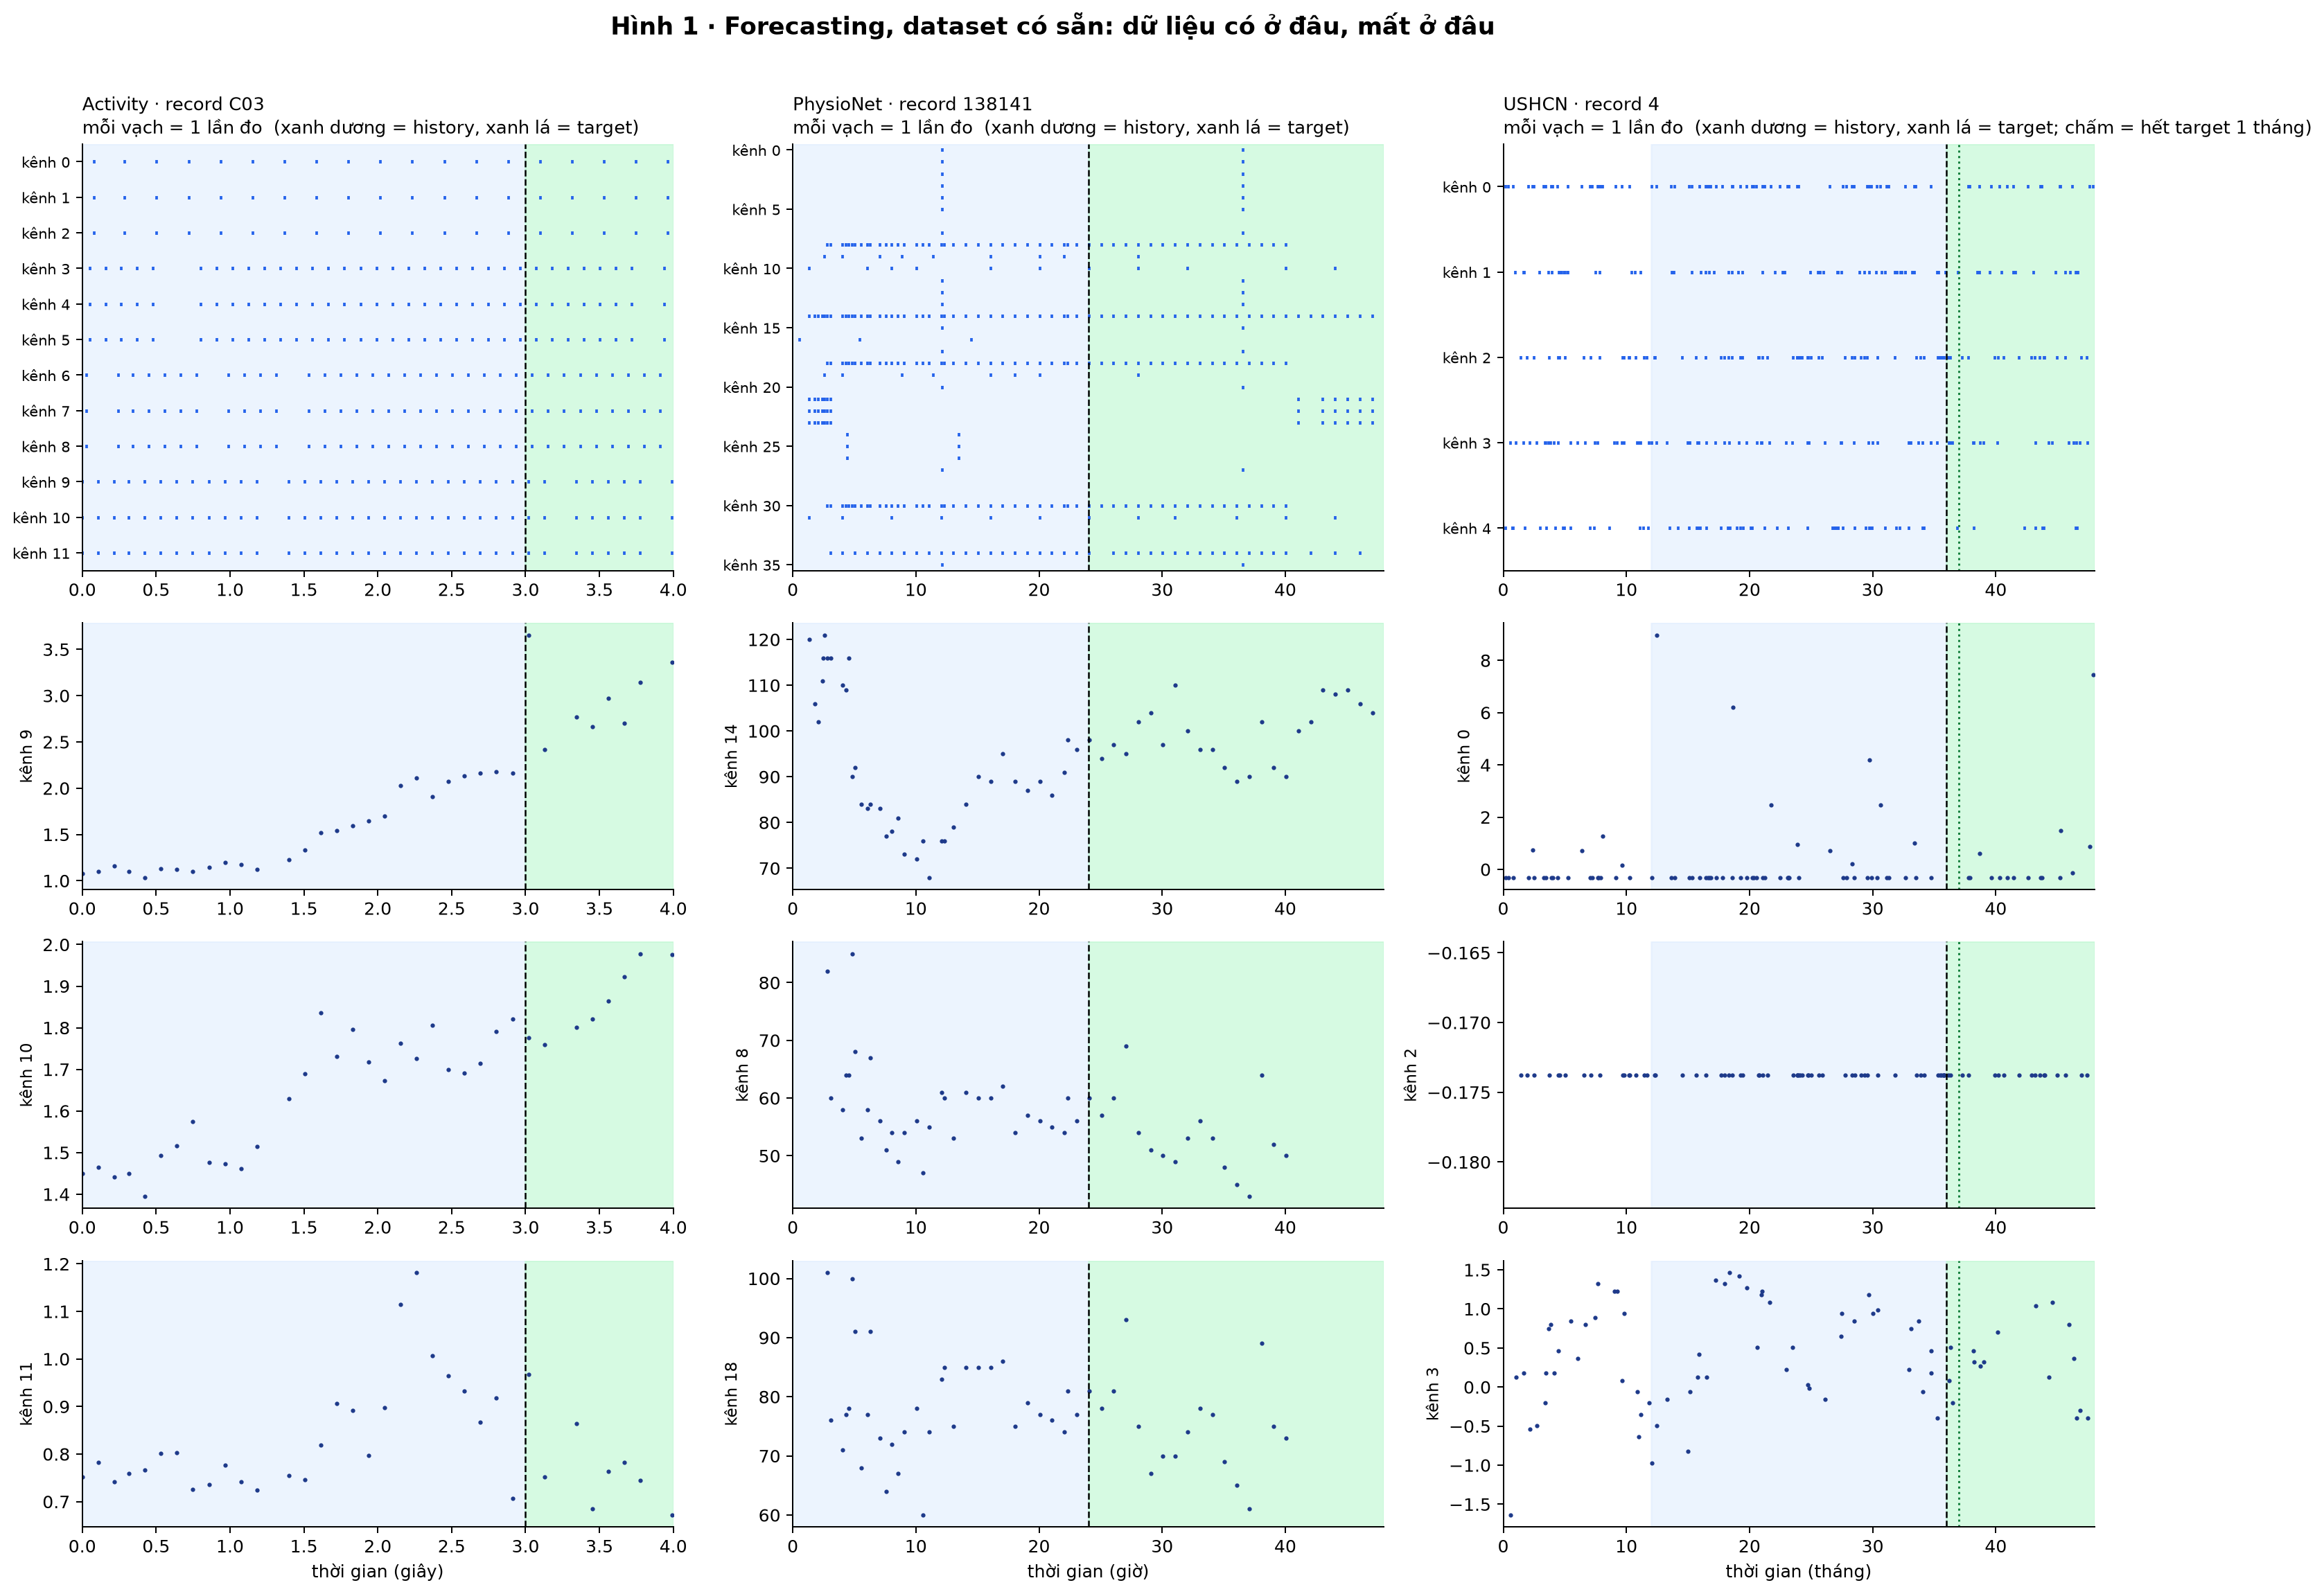

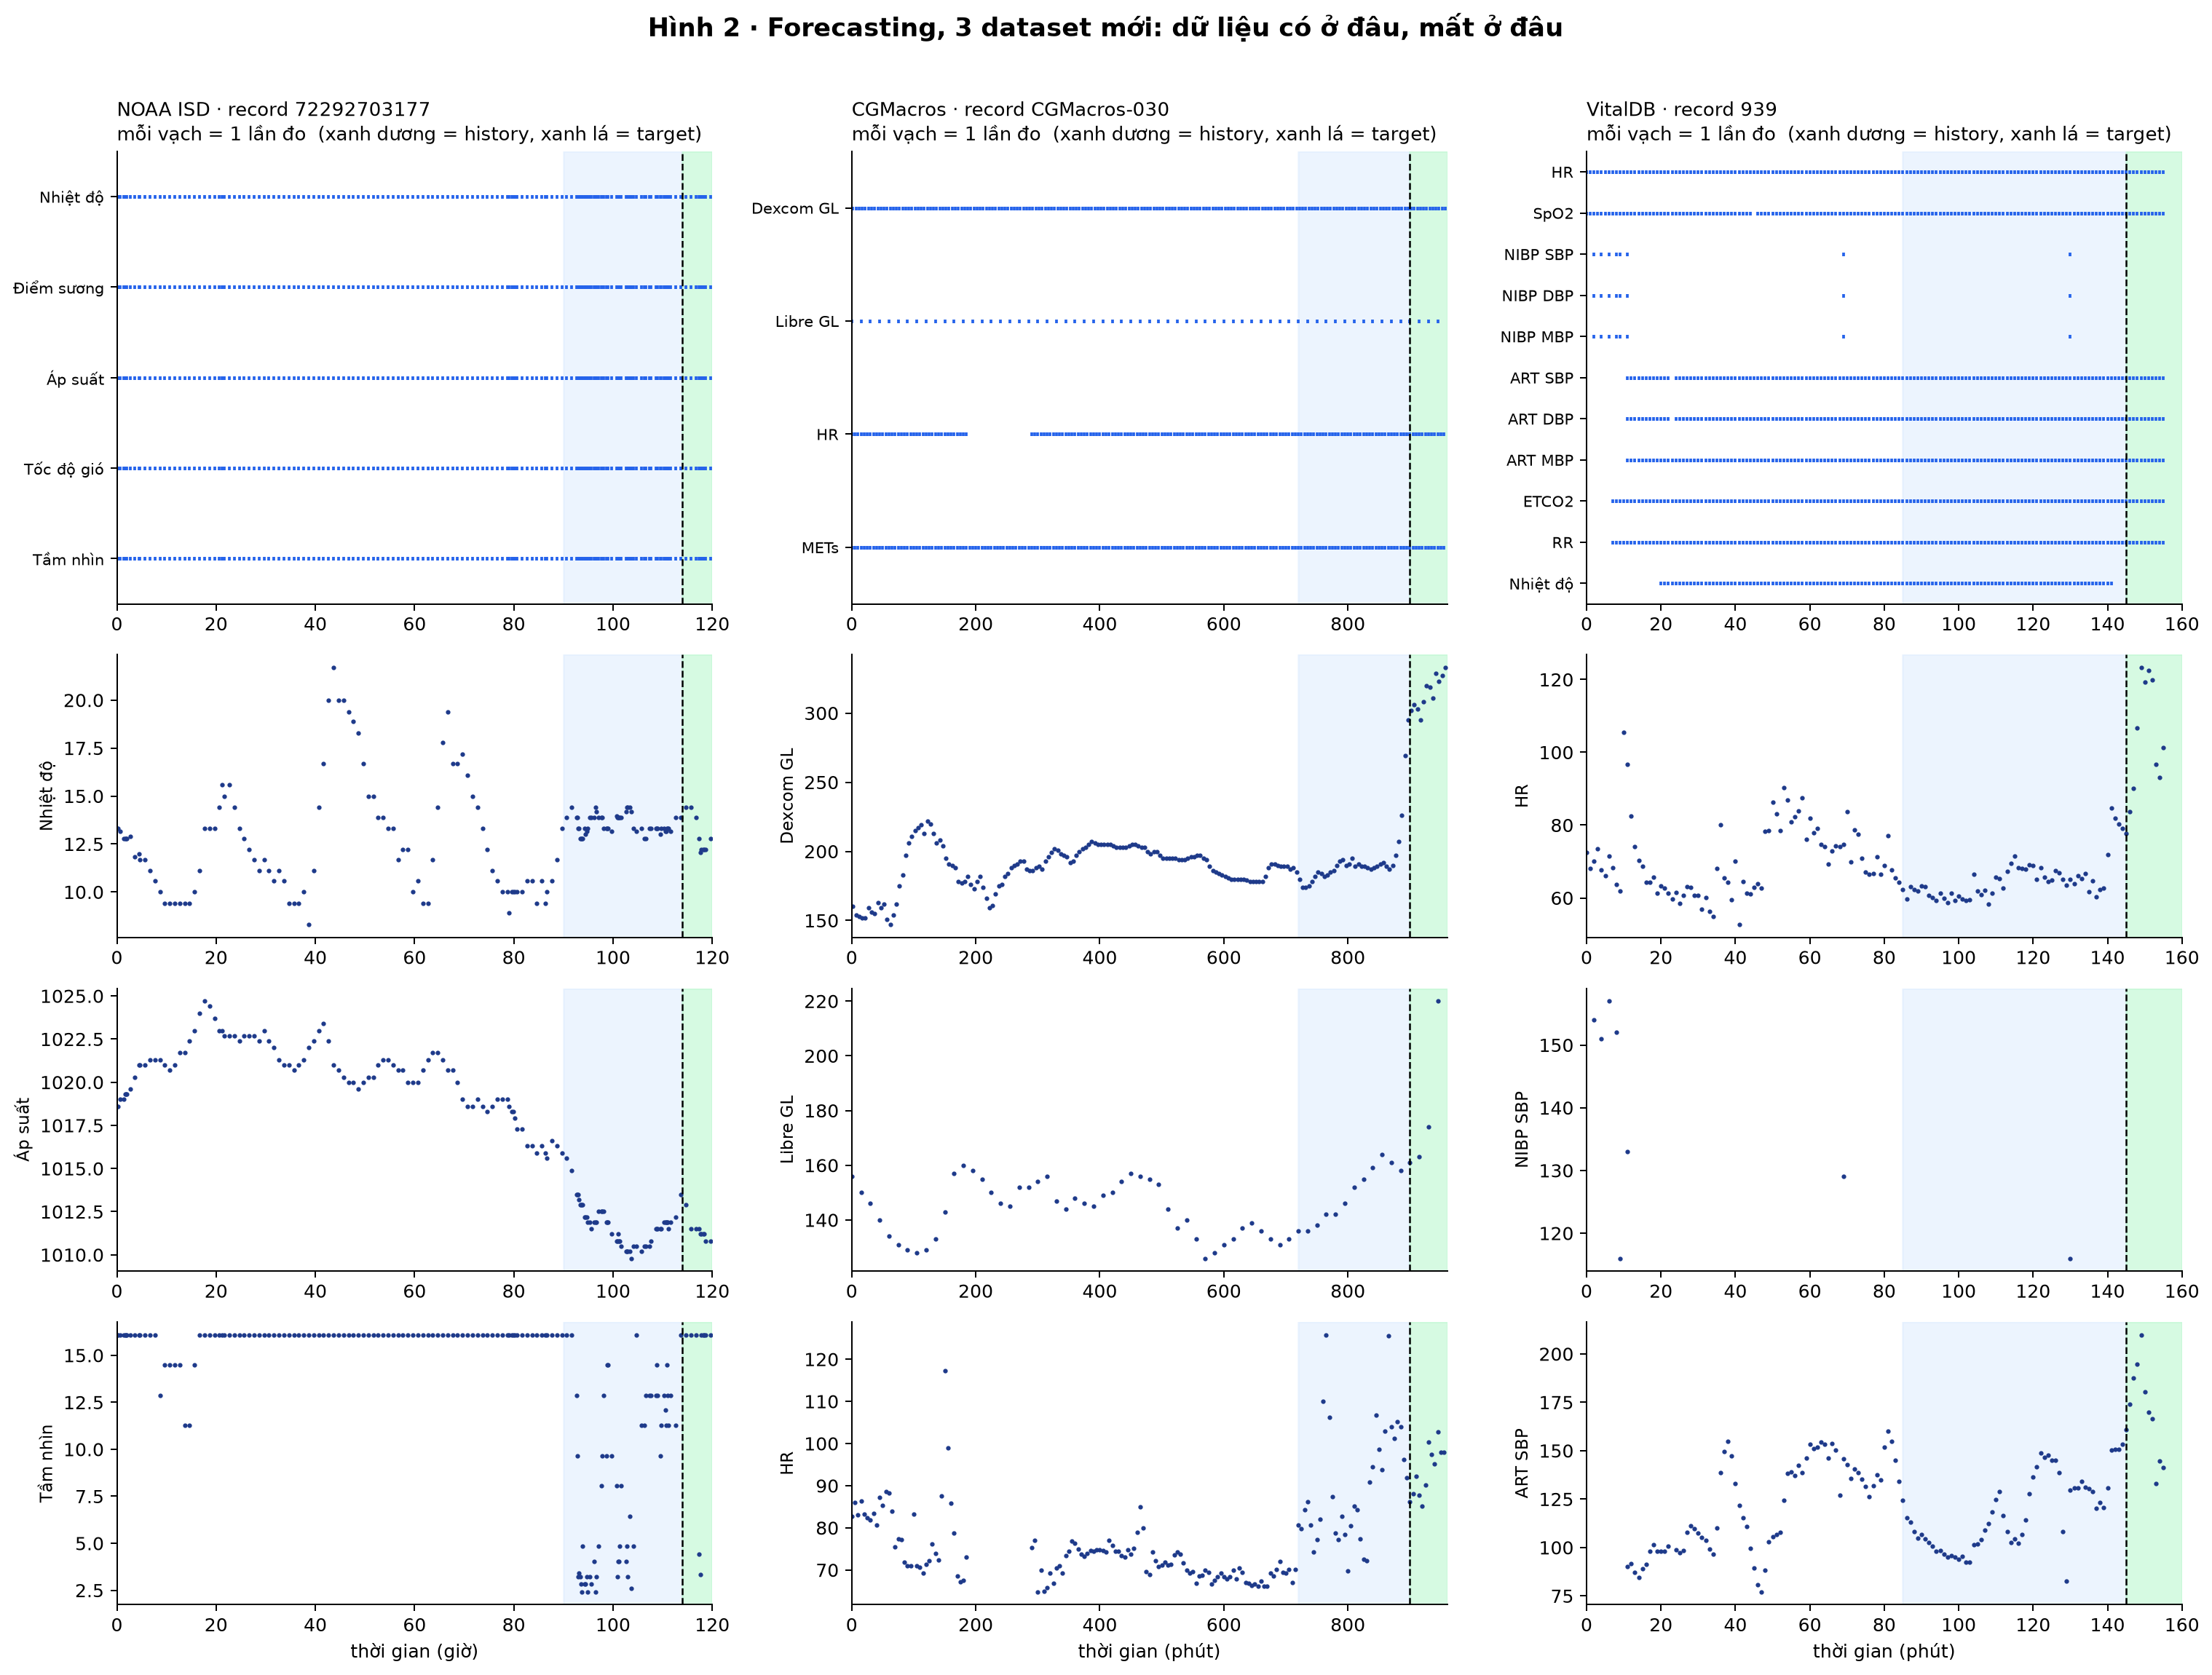

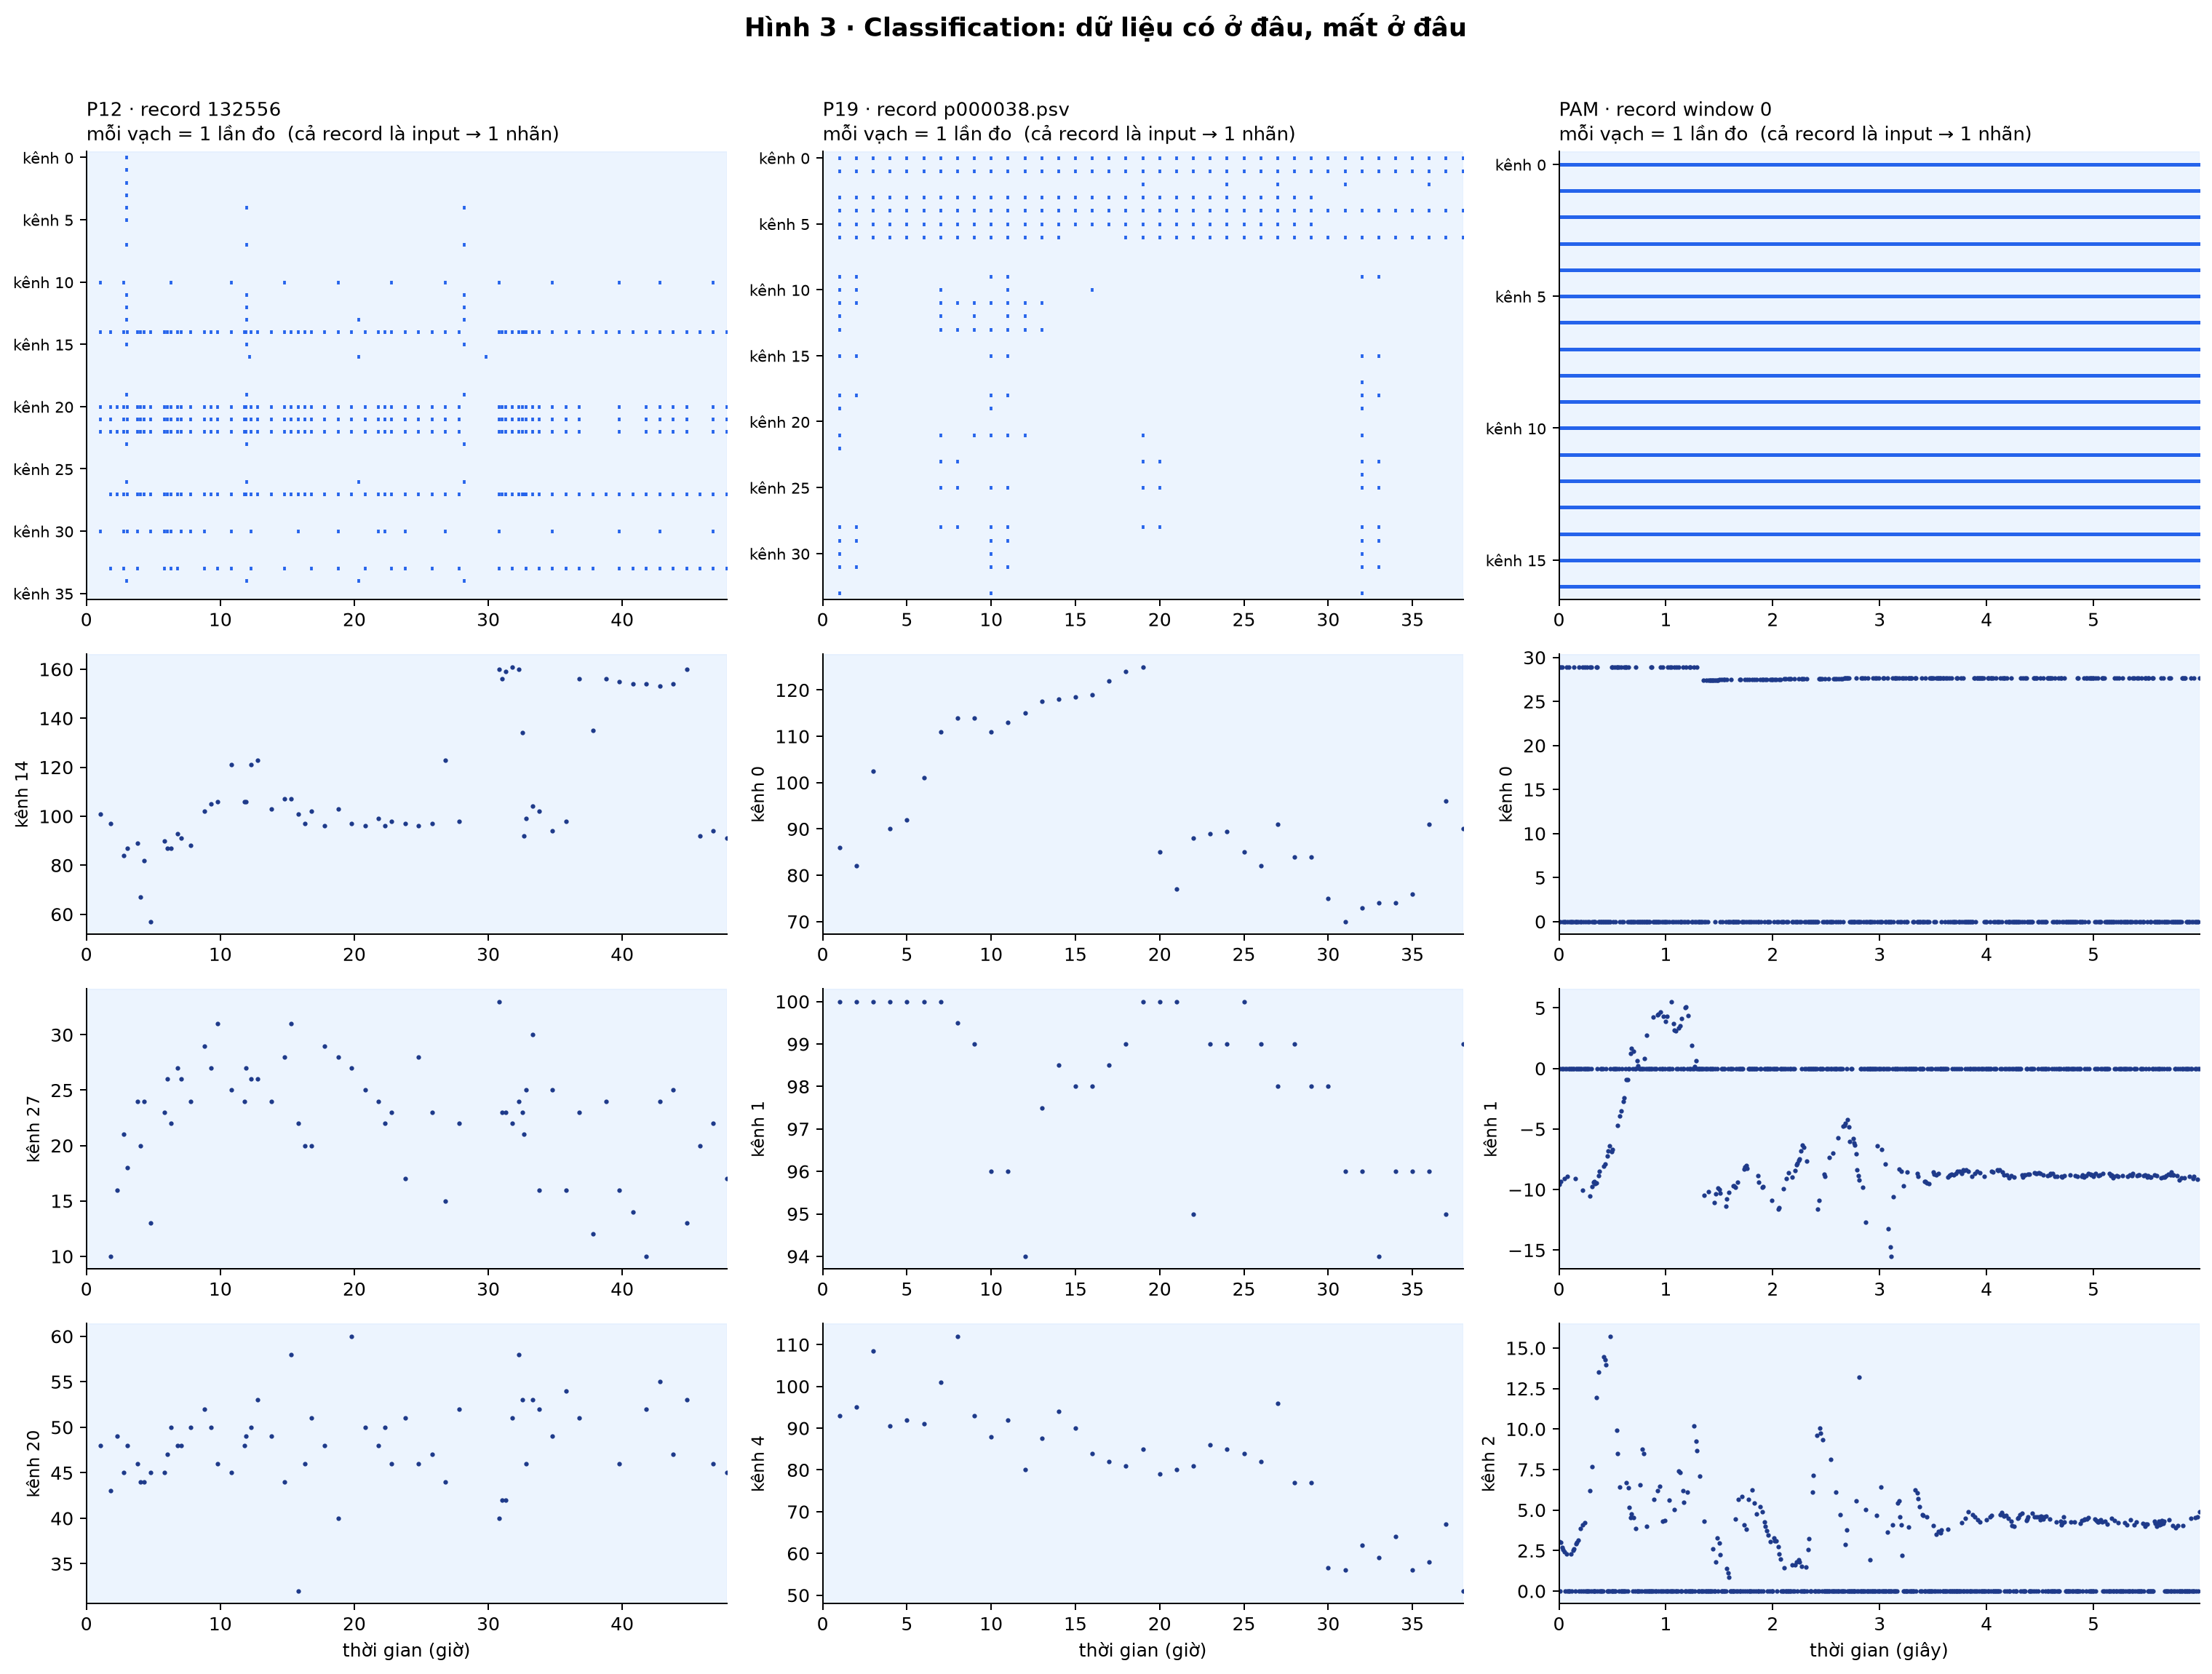

,record,độ rộng bin,số bin,bin trống,phép đo / bin: min,median,max
dataset,,,,,,,
Activity,C03,0.1 giây,40,0,3,9.0,12
PhysioNet,138141,1 giờ,48,0,1,5.5,25
USHCN,4,1 tháng,48,0,2,7.0,14
NOAA ISD,72292703177,1 giờ,120,0,5,5.0,25
CGMacros,CGMacros-030,15 phút,64,0,7,10.0,10
VitalDB,939,1 phút,155,0,2,8.0,14
P12,132556,1 giờ,47,0,1,8.0,26
P19,p000038.psv,1 giờ,37,0,4,6.0,21
PAM,window 0,0.1 giây,60,0,153,170.0,187


In [6]:
# Một record đại diện của mỗi dataset, vẽ cùng một kiểu cho cả 9 dataset:
# hàng trên = mỗi vạch là một lần đo (kênh × thời gian); 3 hàng dưới = giá trị của 3 kênh.
# Forecasting: vùng xanh dương = history, vùng xanh lá = target của một cửa sổ benchmark, vạch đứt = ranh giới.
# Classification: cả record là input (xanh dương), đầu ra là một nhãn nên không có vùng target.
# Dataset có sẵn: record có số timestamp gần median nhất, 3 kênh đo nhiều nhất.
# Dataset mới: record gần median và có đủ mọi kênh, 3 kênh tiêu biểu.
def pick_old(recs):
    lengths = np.array([len(t) for _, t, _, _ in recs])
    return recs[int(np.argmin(np.abs(lengths - np.median(lengths))))]

def pick_new(recs):
    lengths = np.array([len(t) for _, t, _, _ in recs])
    full = np.array([m.any(0).all() for _, _, _, m in recs])
    return recs[int(np.argmin(np.abs(lengths - np.median(lengths)) + np.where(full, 0, np.inf)))]

def load_classification(name):
    if name == 'PAM':
        pam = np.load(DATA_DIR / 'classification/PAM/PAMAP2data/processed_data/PTdict_list.npy', mmap_mode='r')
        v = np.asarray(pam[0], dtype=float).copy()     # mọi cửa sổ PAM dài bằng nhau; lấy cửa sổ đầu tiên
        return 'window 0', np.arange(len(v)) / 100, v, np.isfinite(v)
    path = {'P12': 'P12/P12data/processed_data/PTdict_list.npy', 'P19': 'P19/P19data/processed_data/PT_dict_list_6.npy'}[name]
    recs = np.load(DATA_DIR / 'classification' / path, allow_pickle=True)
    lengths = np.array([min(int(r['length']), len(r['arr'])) for r in recs])
    i = int(np.argmin(np.abs(lengths - np.median(lengths))))
    r, n = recs[i], lengths[i]
    t = np.asarray(r['time'][:n], dtype=float).reshape(-1) / (60 if name == 'P12' else 1)
    v = np.asarray(r['arr'][:n], dtype=float)
    return str(r['id']).replace('\\', '/').split('/')[-1], t, v, np.isfinite(v) & (v != 0)   # P12/P19: khác 0 = có đo

# (đoạn vẽ, history, dự báo, đơn vị); None = classification. Activity đổi ms -> giây và phóng to 4 giây đầu.
VIEW = {'Activity': (4, 3, 1, 'giây'), 'PhysioNet': (48, 24, 24, 'giờ'), 'USHCN': (48, 24, 12, 'tháng'),
        'NOAA ISD': (120, 24, 6, 'giờ'), 'CGMacros': (960, 180, 60, 'phút'), 'VitalDB': (160, 60, 15, 'phút'),
        'P12': (None, None, None, 'giờ'), 'P19': (None, None, None, 'giờ'), 'PAM': (None, None, None, 'giây')}
SHOW = {'NOAA ISD': [0, 2, 4], 'CGMacros': [0, 1, 2], 'VitalDB': [0, 2, 5]}
BIN = {'Activity': .1, 'PhysioNet': 1, 'USHCN': 1, 'NOAA ISD': 1, 'CGMacros': 15, 'VitalDB': 1,
       'P12': 1, 'P19': 1, 'PAM': .1}

shown = {}
for name in ['Activity', 'PhysioNet', 'USHCN', *NEW_SOURCES]:
    rid, t, v, m = (pick_new if name in NEW_SOURCES else pick_old)(records[name])
    span = VIEW[name][0]
    if name == 'Activity':
        t, t0 = (t - t.min()) / 1000, 0.
    elif name in NEW_SOURCES:
        t0 = t.min() + (span * 2 if t.max() - t.min() > span * 3 else 0)
    else:
        t0 = 0.
    keep = (t >= t0) & (t < t0 + span)
    shown[name] = (rid, t[keep] - t0, v[keep], m[keep])
for name in ['P12', 'P19', 'PAM']:
    shown[name] = load_classification(name)

def draw(names, title, fname):
    fig, axes = plt.subplots(4, 3, figsize=(17, 13), gridspec_kw={'height_ratios': [1.6, 1, 1, 1]})
    for col, name in enumerate(names):
        rid, t, v, m = shown[name]
        m = m & np.isfinite(v)
        span, H, F, unit = VIEW[name]
        xmax = span or t.max()
        n_ch = m.shape[1]
        labels = SOURCES[name][2] if name in NEW_SOURCES else [f'kênh {c}' for c in range(n_ch)]
        chans = SHOW.get(name) or list(np.argsort(-m.sum(0), kind='stable')[:3])

        def shade(ax):
            if H is None:
                ax.axvspan(0, xmax, color='#dbeafe', alpha=.5, zorder=0)
                return
            b = span - F                                   # cửa sổ cuối cùng của đoạn vẽ
            ax.axvspan(b - H, b, color='#dbeafe', alpha=.5, zorder=0)
            ax.axvspan(b, b + F, color='#bbf7d0', alpha=.6, zorder=0)
            ax.axvline(b, color='black', ls='--', lw=1)
            if name == 'USHCN':                            # horizon 1 tháng: cùng history, target chỉ 1 bước
                ax.axvline(b + 1, color='#15803d', ls=':', lw=1.2)

        ax = axes[0, col]
        for c in range(n_ch):
            ax.scatter(t[m[:, c]], np.full(m[:, c].sum(), c), s=4, marker='|', color='#2563eb')
        shade(ax)
        step = 1 if n_ch <= 12 else 5
        ax.set_yticks(range(0, n_ch, step), [labels[c] for c in range(0, n_ch, step)], fontsize=8.5)
        ax.set_ylim(n_ch - .5, -.5)
        ax.set_xlim(0, xmax)
        kind = 'cả record là input → 1 nhãn' if H is None else 'xanh dương = history, xanh lá = target'
        extra = '; chấm = hết target 1 tháng' if name == 'USHCN' else ''
        ax.set_title(f'{name} · record {rid}\nmỗi vạch = 1 lần đo  ({kind}{extra})', fontsize=10.5, loc='left')
        for row, c in enumerate(chans, start=1):
            ax = axes[row, col]
            ax.plot(t[m[:, c]], v[m[:, c], c], '.', ms=3, color='#1e3a8a')
            shade(ax)
            ax.set_xlim(0, xmax)
            ax.set_ylabel(labels[c], fontsize=9)
            ax.ticklabel_format(axis='y', style='plain', useOffset=False)
            if row == 3:
                ax.set_xlabel(f'thời gian ({unit})')
    fig.suptitle(title, fontsize=14, fontweight='bold')
    fig.tight_layout(rect=(0, 0, 1, .97))
    save_figure(fig, fname)

draw(['Activity', 'PhysioNet', 'USHCN'], 'Hình 1 · Forecasting, dataset có sẵn: dữ liệu có ở đâu, mất ở đâu', 'time_forecast_existing')
draw(NEW_SOURCES, 'Hình 2 · Forecasting, 3 dataset mới: dữ liệu có ở đâu, mất ở đâu', 'time_forecast_new')
draw(['P12', 'P19', 'PAM'], 'Hình 3 · Classification: dữ liệu có ở đâu, mất ở đâu', 'time_classification')

# Đếm phép đo theo bin thời gian cố định trên đúng đoạn đã vẽ: có bin nào trống hoàn toàn không?
bin_rows = []
for name, (rid, t, v, m) in shown.items():
    m = m & np.isfinite(v)
    w = BIN[name]
    start, stop = np.floor(t.min() / w) * w, np.ceil(t.max() / w) * w   # từ lần đo đầu đến lần đo cuối
    edges = start + np.arange(max(1, int(round((stop - start) / w))) + 1) * w
    counts, _ = np.histogram(np.repeat(t, m.sum(1)), bins=edges)
    bin_rows.append({'dataset': name, 'record': rid, 'độ rộng bin': f'{w:g} {VIEW[name][3]}', 'số bin': len(counts),
                     'bin trống': int((counts == 0).sum()), 'phép đo / bin: min': int(counts.min()),
                     'median': float(np.median(counts)), 'max': int(counts.max())})
display(pd.DataFrame(bin_rows).set_index('dataset'))

**Kết luận:** chỉ dữ liệu ICU (PhysioNet, P12, P19) bất quy tắc thật: vài kênh đo hàng giờ cộng các đợt xét nghiệm. Activity và PAM đo đều trên lưới cố định. CGMacros: Dexcom dày, Libre thưa hơn. **Không record nào có khoảng thời gian trống hoàn toàn** (cột "bin trống" toàn 0), nên bất quy tắc trong benchmark gần như toàn do xóa nhân tạo.

<a id="phan-2-2"></a>

## 2.2 Shift trong benchmark so với shift thật

Shift trong benchmark là xóa nhân tạo theo một quy tắc cố định (density: bỏ mỗi lần đo với xác suất 0.7; timing: mỗi kênh giữ 1 trên 3 lần đo; variables: bỏ một nửa số kênh). Mục này so chúng với **hai shift thật có sẵn trong dữ liệu**, không cần model:
- **P19, đổi bệnh viện:** mỗi record ghi rõ bệnh viện A hay B (19,577 và 19,226 bệnh nhân). Paper dùng đúng shift này ("held-out hospital").
- **CGMacros, đổi thiết bị:** cùng người, cùng lúc, đường huyết được đo bằng hai máy Dexcom và Libre.

<a id="hinh-2-2"></a>

#### 📈 Hình 2.2 · Shift nhân tạo so với shift thật

- **(a)** P19, mỗi chấm = 1 kênh. Trục x = % giờ có đo ở bệnh viện A, trục y = ở bệnh viện B (log). Đường liền = không đổi; đường đứt = vị trí mọi kênh sẽ nằm nếu shift là density (×0.3). Tên kênh ghi ở các kênh đổi hơn 1.6 lần.
- **(b)** Mỗi cột = một loại shift áp lên bệnh viện A; mỗi chấm = 1 kênh; trục y = % giờ có đo sau shift ÷ trước shift (log, 1 = không đổi). Số phía trên = tổng số lần đo còn lại. Bỏ EtCO2 vì bệnh viện A gần như không đo.
- **(c)** % bệnh nhân có nhãn sepsis: bệnh viện A, A sau shift nhân tạo (nhãn giữ nguyên), bệnh viện B.
- **(d)** CGMacros, một ngày của người có độ lệch Dexcom–Libre gần median: chấm xanh = Dexcom, chấm cam = Libre.
- **(e)** Khoảng cách giữa hai lần đo liên tiếp của mỗi máy.
- **(f)** Mỗi chấm = một lần đo Libre ghép với lần đo Dexcom gần nhất (lệch ≤ 2.5 phút). Đường liền = hai máy cho cùng giá trị; đường đứt = lệch trung bình.
- **Bảng dưới hình:** số liệu của (a)–(c) và (e)–(f).

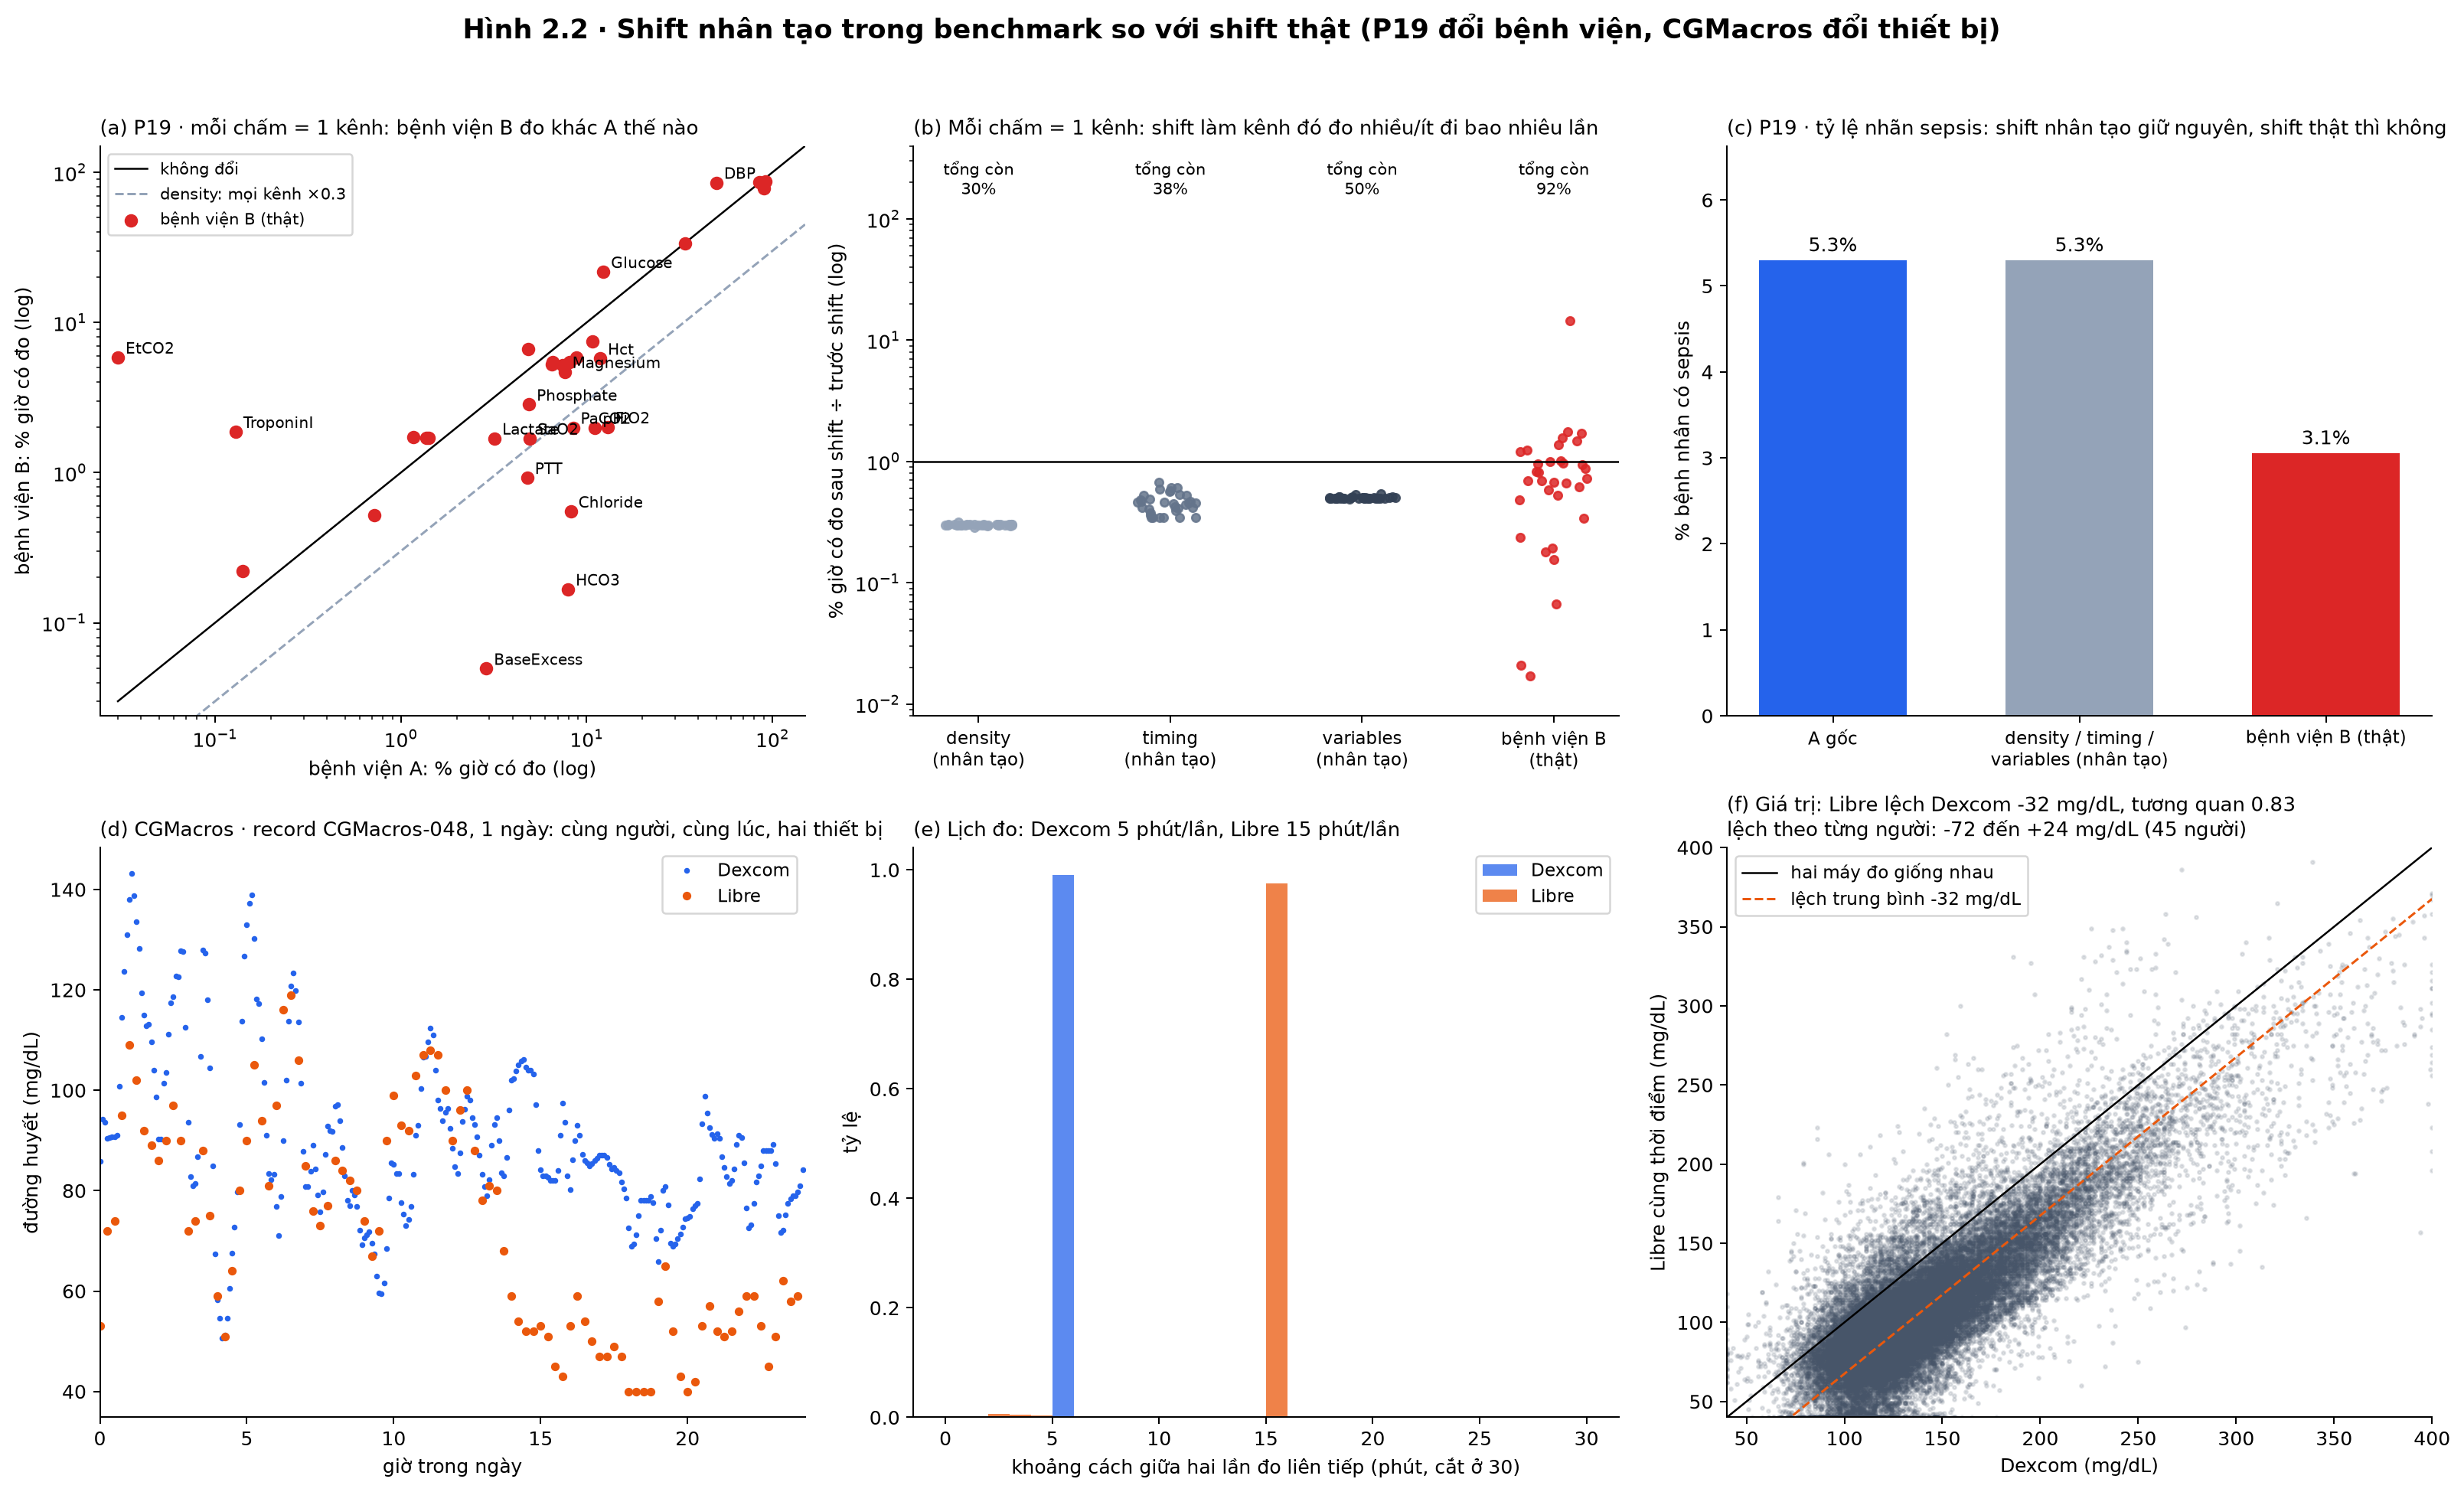

,lần đo / giờ (median theo record),tổng lần đo còn lại (% của A),kênh tăng > 1.5 lần,kênh giảm > 1.5 lần,% sepsis
shift,,,,,
A gốc,6.70,100.00,0,0,5.30
density (nhân tạo),2.00,30.01,0,33,5.30
timing (nhân tạo),2.53,37.86,0,32,5.30
variables (nhân tạo),3.36,49.91,0,33,5.30
bệnh viện B (thật),6.53,92.32,4,13,3.06


,Dexcom,Libre
"khoảng cách đo (phút, median)",5.0,15.0
số lần đo,126892.0,46916.0


CGMacros: 42975 cặp đo (Libre và Dexcom lệch ≤ 2.5 phút) ở 45 người; Libre − Dexcom trung bình -32.5 mg/dL, tương quan 0.83; theo từng người: median -33.8, từ -71.7 đến +24.2 mg/dL


In [7]:
# Shift thật so với shift nhân tạo, chỉ nhìn dữ liệu (chưa có model).
# Shift thật 1: P19, bệnh viện A → bệnh viện B (id record ghi trainingA / trainingB). "Có đo" = giá trị khác 0.
# Shift thật 2: CGMacros, cùng đường huyết nhưng đo bằng Dexcom hoặc Libre.
# Shift nhân tạo áp lên bệnh viện A đúng như paper mô tả: density = bỏ mỗi lần đo với xác suất 0.7;
# timing = mỗi kênh giữ 1 trên 3 lần đo; variables = bỏ một nửa số kênh. (composed = timing + bỏ nhóm kênh liền nhau, không vẽ.)
P19_NAMES = ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2',
             'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose',
             'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT',
             'WBC', 'Fibrinogen', 'Platelets']
p19_dir = DATA_DIR / 'classification' / 'P19' / 'P19data' / 'processed_data'
p19 = np.load(p19_dir / 'PT_dict_list_6.npy', allow_pickle=True)
sepsis = np.load(p19_dir / 'arr_outcomes_6.npy', allow_pickle=True)[:, -1].astype(float)
hosp_b = np.array(['trainingB' in r['id'] for r in p19])
masks = []
for r in p19:
    n = min(int(r['length']), len(r['arr']))
    masks.append((r['arr'][:n] != 0) & np.isfinite(r['arr'][:n]))

rng = np.random.default_rng(0)
def density(m):
    return m & (rng.random(m.shape) < .3)
def timing(m):
    return m & (np.cumsum(m, 0) % 3 == 1)
def variables(m):
    keep = np.zeros(m.shape[1], bool)
    keep[rng.permutation(m.shape[1])[:m.shape[1] // 2]] = True
    return m & keep[None]

def profile_of(ms):
    hours = sum(len(m) for m in ms)
    return (np.sum([m.sum(0) for m in ms], 0) / hours * 100,            # % giờ có đo, theo kênh
            np.array([m.sum() / len(m) for m in ms]))                    # lần đo / giờ, theo record
masks_a = [m for m, b in zip(masks, hosp_b) if not b]
masks_b = [m for m, b in zip(masks, hosp_b) if b]
SCEN = {'A gốc': masks_a, 'density (nhân tạo)': [density(m) for m in masks_a],
        'timing (nhân tạo)': [timing(m) for m in masks_a], 'variables (nhân tạo)': [variables(m) for m in masks_a],
        'bệnh viện B (thật)': masks_b}
prof = {k: profile_of(v) for k, v in SCEN.items()}
rate_a = prof['A gốc'][0]
measured_a = rate_a > .05                                               # bỏ kênh A gần như không đo (EtCO2) khỏi tỷ lệ
ratio = {k: prof[k][0][measured_a] / rate_a[measured_a] for k in SCEN if k != 'A gốc'}

# CGMacros: Dexcom (kênh 0) và Libre (kênh 1) trên cùng record.
# Ghép mỗi lần đo Libre với lần đo Dexcom gần nhất (lệch ≤ 2.5 phút) để so giá trị.
gap_dx, gap_lb, same_t, person_bias = [], [], [], {}
for rid, t, v, m in records['CGMacros']:
    td, vd, tl, vl = t[m[:, 0]], v[m[:, 0], 0], t[m[:, 1]], v[m[:, 1], 1]
    gap_dx += list(np.diff(td))
    gap_lb += list(np.diff(tl))
    if len(td) == 0:
        continue
    j = np.clip(np.searchsorted(td, tl), 1, len(td) - 1)
    j = np.where(np.abs(td[j - 1] - tl) < np.abs(td[j] - tl), j - 1, j)
    ok = np.abs(td[j] - tl) <= 2.5
    if ok.sum() > 100:
        same_t += list(zip(vd[j[ok]], vl[ok]))
        person_bias[rid] = (vl[ok] - vd[j[ok]]).mean()
gap_dx, gap_lb, same_t = np.array(gap_dx), np.array(gap_lb), np.array(same_t)
bias = (same_t[:, 1] - same_t[:, 0]).mean()
corr = np.corrcoef(same_t.T)[0, 1]
pb = np.array(list(person_bias.values()))

SC_COLOR = {'density (nhân tạo)': '#94a3b8', 'timing (nhân tạo)': '#64748b', 'variables (nhân tạo)': '#334155',
            'bệnh viện B (thật)': '#dc2626'}
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

ax = axes[0, 0]                                                          # (a) từng kênh: A so với B
rate_b = prof['bệnh viện B (thật)'][0]
lo = .03
xa, xb = np.maximum(rate_a, lo), np.maximum(rate_b, lo)
ax.plot([lo, 150], [lo, 150], color='black', lw=1, label='không đổi')
ax.plot([lo, 150], [lo * .3, 150 * .3], color='#94a3b8', ls='--', lw=1.2, label='density: mọi kênh ×0.3')
ax.scatter(xa, xb, s=36, color='#dc2626', zorder=3, label='bệnh viện B (thật)')
for c in np.where(np.abs(np.log(xb / xa)) > np.log(1.6))[0]:
    ax.annotate(P19_NAMES[c], (xa[c], xb[c]), fontsize=8, xytext=(4, 2), textcoords='offset points')
ax.set(xscale='log', yscale='log', xlim=(lo * .8, 150), ylim=(lo * .8, 150),
       xlabel='bệnh viện A: % giờ có đo (log)', ylabel='bệnh viện B: % giờ có đo (log)')
ax.set_title('(a) P19 · mỗi chấm = 1 kênh: bệnh viện B đo khác A thế nào', loc='left', fontsize=10.5)
ax.legend(fontsize=8.5, loc='upper left')

ax = axes[0, 1]                                                          # (b) tỷ lệ đổi theo kênh, mỗi loại shift
for i, (k, rr) in enumerate(ratio.items()):
    rr = np.clip(rr, .01, 100)
    ax.scatter(i + rng.uniform(-.18, .18, len(rr)), rr, s=18, color=SC_COLOR[k], alpha=.85)
    tot = prof[k][1].mean() / prof['A gốc'][1].mean() * 100
    ax.text(i, 160, f'tổng còn\n{tot:.0f}%', ha='center', fontsize=8.5)
ax.axhline(1, color='black', lw=1)
ax.set(yscale='log', ylim=(.008, 400), ylabel='% giờ có đo sau shift ÷ trước shift (log)')
ax.set_xticks(range(len(ratio)), [k.replace(' (', '\n(') for k in ratio], fontsize=9)
ax.set_title('(b) Mỗi chấm = 1 kênh: shift làm kênh đó đo nhiều/ít đi bao nhiêu lần', loc='left', fontsize=10.5)

ax = axes[0, 2]                                                          # (c) nhãn có giữ nguyên không
rates = {'A gốc': sepsis[~hosp_b].mean() * 100, 'density / timing /\nvariables (nhân tạo)': sepsis[~hosp_b].mean() * 100,
         'bệnh viện B (thật)': sepsis[hosp_b].mean() * 100}
bars = ax.bar(range(3), list(rates.values()), color=['#2563eb', '#94a3b8', '#dc2626'], width=.6)
for b_, v_ in zip(bars, rates.values()):
    ax.text(b_.get_x() + b_.get_width() / 2, v_ + .1, f'{v_:.1f}%', ha='center', fontsize=10)
ax.set_xticks(range(3), list(rates.keys()), fontsize=9)
ax.set(ylabel='% bệnh nhân có sepsis', ylim=(0, max(rates.values()) * 1.25))
ax.set_title('(c) P19 · tỷ lệ nhãn sepsis: shift nhân tạo giữ nguyên, shift thật thì không', loc='left', fontsize=10.5)

ax = axes[1, 0]                                                          # (d) một ngày của một record CGMacros
typical = min(person_bias, key=lambda k: abs(person_bias[k] - np.median(pb)))   # người có độ lệch gần median
rid, t, v, m = next(r for r in records['CGMacros'] if r[0] == typical)
t0 = t.min() + 1440
keep = (t >= t0) & (t < t0 + 1440)
for c, col, lab in [(0, '#2563eb', 'Dexcom'), (1, '#ea580c', 'Libre')]:
    k = keep & m[:, c]
    ax.plot((t[k] - t0) / 60, v[k, c], '.', ms=4 if c == 0 else 7, color=col, label=lab)
ax.set(xlabel='giờ trong ngày', ylabel='đường huyết (mg/dL)', xlim=(0, 24))
ax.set_title(f'(d) CGMacros · record {rid}, 1 ngày: cùng người, cùng lúc, hai thiết bị', loc='left', fontsize=10.5)
ax.legend(fontsize=9)

ax = axes[1, 1]                                                          # (e) khoảng cách giữa hai lần đo
bins = np.arange(0, 31, 1)
ax.hist(np.clip(gap_dx, 0, 30), bins=bins, color='#2563eb', alpha=.75, label='Dexcom', density=True)
ax.hist(np.clip(gap_lb, 0, 30), bins=bins, color='#ea580c', alpha=.75, label='Libre', density=True)
ax.set(xlabel='khoảng cách giữa hai lần đo liên tiếp (phút, cắt ở 30)', ylabel='tỷ lệ')
ax.set_title(f'(e) Lịch đo: Dexcom {np.median(gap_dx):.0f} phút/lần, Libre {np.median(gap_lb):.0f} phút/lần',
             loc='left', fontsize=10.5)
ax.legend(fontsize=9)

ax = axes[1, 2]                                                          # (f) giá trị cùng thời điểm
ax.scatter(same_t[:, 0], same_t[:, 1], s=3, alpha=.15, color='#475569')
ax.plot([40, 400], [40, 400], color='black', lw=1, label='hai máy đo giống nhau')
ax.plot([40, 400], [40 + bias, 400 + bias], color='#ea580c', ls='--', lw=1.2, label=f'lệch trung bình {bias:+.0f} mg/dL')
ax.set(xlabel='Dexcom (mg/dL)', ylabel='Libre cùng thời điểm (mg/dL)', xlim=(40, 400), ylim=(40, 400))
ax.set_title(f'(f) Giá trị: Libre lệch Dexcom {bias:+.0f} mg/dL, tương quan {corr:.2f}\n'
             f'lệch theo từng người: {pb.min():+.0f} đến {pb.max():+.0f} mg/dL ({len(pb)} người)', loc='left', fontsize=10.5)
ax.legend(fontsize=9, loc='upper left')

fig.suptitle('Hình 2.2 · Shift nhân tạo trong benchmark so với shift thật (P19 đổi bệnh viện, CGMacros đổi thiết bị)',
             fontsize=14, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, .96))
save_figure(fig, 'real_vs_artificial_shift')

# Bảng số liệu của hình.
rows = []
for k in SCEN:
    rr = ratio.get(k, np.ones(measured_a.sum()))
    rows.append({'shift': k, 'lần đo / giờ (median theo record)': np.median(prof[k][1]),
                 'tổng lần đo còn lại (% của A)': prof[k][1].mean() / prof['A gốc'][1].mean() * 100,
                 'kênh tăng > 1.5 lần': int((rr > 1.5).sum()), 'kênh giảm > 1.5 lần': int((rr < 1 / 1.5).sum()),
                 '% sepsis': (sepsis[hosp_b] if k.startswith('bệnh viện B') else sepsis[~hosp_b]).mean() * 100})
display(pd.DataFrame(rows).set_index('shift').round(2))
display(pd.DataFrame({'Dexcom': [np.median(gap_dx), sum(r[3][:, 0].sum() for r in records['CGMacros'])],
                      'Libre': [np.median(gap_lb), sum(r[3][:, 1].sum() for r in records['CGMacros'])]},
                     index=['khoảng cách đo (phút, median)', 'số lần đo']).round(1))
print(f'CGMacros: {len(same_t)} cặp đo (Libre và Dexcom lệch ≤ 2.5 phút) ở {len(pb)} người; '
      f'Libre − Dexcom trung bình {bias:+.1f} mg/dL, tương quan {corr:.2f}; '
      f'theo từng người: median {np.median(pb):+.1f}, từ {pb.min():+.1f} đến {pb.max():+.1f} mg/dL')

**Kết luận:** shift nhân tạo và shift thật khác nhau ở cả hình dạng lẫn những gì nó làm thay đổi.
- **Shift nhân tạo giảm đều mọi kênh** ((b), ba cột xám): tổng số lần đo chỉ còn 30% / 38% / 50%, và mọi kênh giảm gần cùng một tỷ lệ.
- **Shift thật gần như giữ nguyên tổng lượng đo nhưng xáo trộn từng kênh** ((a), (b) cột đỏ): bệnh viện B vẫn có 92% lượng đo (6.5 so với 6.7 lần/giờ), nhưng 13/33 kênh giảm hơn 1.5 lần (HCO3, BaseExcess ×0.02; Chloride ×0.07; pH ×0.18) và 4 kênh tăng (TroponinI ×15, Glucose ×1.8, DBP ×1.7). EtCO2 chỉ bệnh viện B đo. Không có loại shift nhân tạo nào tạo ra kiểu thay đổi này.
- **Shift thật đổi cả nhãn và giá trị, không chỉ lịch đo** ((c), (f)): tỷ lệ sepsis giảm từ 5.3% xuống 3.1%. Libre đo thưa gấp 3 lần Dexcom (15 so với 5 phút/lần, giống timing) nhưng giá trị thấp hơn trung bình 32 mg/dL, mức lệch khác nhau theo từng người (−72 đến +24 mg/dL). Hai shift này vi phạm giả định của paper rằng chỉ lịch đo thay đổi, còn tín hiệu và nhãn giữ nguyên.
- **Trên hai shift thật đã chạy, OPERA gần như hòa Vanilla:** P19 bệnh viện B +0.3% (iTransformer) / −0.6% (PatchTST); eICU vùng khác +1.7% / −2.5%. Trên P19 với shift nhân tạo, OPERA thắng +3.3% (iTransformer) và +2.7% (PatchTST) ([[Hình 3.1]](#hinh-3-1): khối Native shift, cột Clean).
- **Forecasting chưa có shift thật nào được chạy.** CGMacros Dexcom → Libre là ứng viên có sẵn, nhưng phải tính đến độ lệch giá trị ở (f).

**Điều này dẫn tới:**
- **Mức thắng lớn trên benchmark không phải bằng chứng cho shift thật.** OPERA thắng đậm chủ yếu khi Vanilla sụp vì input thưa hẳn đi ([[Hình 3.2]](#hinh-3-2)). Shift thật giữ nguyên độ dày của input (92%), nên không có cú sụp đó, và OPERA cũng không còn gì nhiều để gỡ. Điều này khớp với mức gần như hòa ở trên.
- **Một phần của shift thật nằm ngoài phạm vi OPERA.** OPERA chỉ xử lý lịch đo; phần lệch về nhãn (sepsis 5.3% → 3.1%) và giá trị (Libre −32 mg/dL) vẫn còn dù xử lý lịch đo tốt đến đâu. Chạy Dexcom → Libre mà không hiệu chỉnh độ lệch giá trị sẽ trộn lẫn hai nguồn này.
- **Benchmark đo đúng độ bền khi input bị thưa đi, nhưng chưa đo được độ bền khi đổi bệnh viện hay đổi thiết bị.** Muốn đo được, shift test cần giống thực tế hơn: đổi tỷ lệ đo khác nhau giữa các kênh (có kênh tăng, có kênh giảm), bỏ cả nhóm xét nghiệm cùng lúc, và có shift thật cho forecasting.

*Mức chắc chắn: kết quả OPERA trên shift thật mới có 2 setting × 2 backbone × 5 seed và lẫn lộn (2 dương, 2 âm): đủ để nói "không thắng rõ", chưa đủ để nói "thua". Chưa tách được OPERA không thắng là do xáo trộn kênh hay do nhãn, giá trị đổi.*

<a id="phan-3"></a>

# 3. Vì sao OPERA thắng/thua

[↑ Tóm tắt](#summary) · [↑ Mục lục](#muc-luc)

<a id="hinh-3-1"></a>

## 3.1 Thắng/thua ở đâu

#### 📈 Hình 3.1 · Bảng màu thắng/thua: mọi model × mọi dataset

- **Hai bảng:** trái = clean, phải = shift (trung bình 4 loại shift).
- **Hàng:** setting (dataset + horizon). Vạch đậm chia 3 khối: forecasting, classification, native shift (test trên bệnh viện/vùng khác).
- **Cột:** 6 model. Vạch đứt tách iTransformer/PatchTST/TMix (bên trái) với GRU-D/mTAND/Warpformer (bên phải).
- **Mỗi ô:** dòng trên = % OPERA hơn/kém Vanilla; dòng dưới = số lần chạy OPERA thắng (clean 5 lần, shift 20 lần). Xanh = thắng, đỏ = thua, xám = hòa (chênh < 0.5% hoặc không áp đảo), "—" = chưa chạy.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb

# Toàn bộ so sánh OPERA vs Vanilla, ghép cặp theo seed, cho mọi nhóm thí nghiệm.
# Thêm 3 dataset forecasting mới (iTransformer, PatchTST, TMix).
new_runs = pd.concat([pd.read_csv(ROOT / 'results' / 'bao_cao' / 'plugin_noaa_cgmacros' / 'benchmark_noaa_cgmacros.csv'),
                      pd.read_csv(ROOT / 'results' / 'bao_cao' / 'plugin_vitaldb' / 'vitaldb.csv')], ignore_index=True)
runs_all = pd.concat([seed, new_runs[seed.columns.intersection(new_runs.columns)]], ignore_index=True)
pairs_all = (runs_all[runs_all.method.isin(['opera', 'vanilla'])]
             .pivot_table(index=['task', 'setting', 'backbone', 'seed', 'condition'], columns='method',
                          values='primary_value').dropna().reset_index())
pairs_all['gain'] = (100 * pairs_all.task.map({'forecast': -1, 'classify': 1})
                     * (pairs_all.opera - pairs_all.vanilla) / pairs_all.vanilla)
pairs_all['state'] = np.where(pairs_all.condition.eq('clean'), 'clean', 'shift')
board = pairs_all.groupby(['setting', 'backbone', 'state']).gain.agg(
    gain='mean', wins=lambda x: (x > 0).sum(), n='size').reset_index()

ROWS = [  # (setting, nhãn, task, loại dữ liệu)
    ('activity_1000ms', 'Activity · 1000ms', 'Forecasting', 'Cảm biến chuyển động'),
    ('activity_2000ms', 'Activity · 2000ms', 'Forecasting', 'Cảm biến chuyển động'),
    ('activity_3000ms', 'Activity · 3000ms', 'Forecasting', 'Cảm biến chuyển động'),
    ('physionet_12h', 'PhysioNet · 12h', 'Forecasting', 'ICU'),
    ('physionet_24h', 'PhysioNet · 24h', 'Forecasting', 'ICU'),
    ('physionet_36h', 'PhysioNet · 36h', 'Forecasting', 'ICU'),
    ('ushcn_1mo', 'USHCN · 1 tháng', 'Forecasting', 'Thời tiết'),
    ('ushcn_6mo', 'USHCN · 6 tháng', 'Forecasting', 'Thời tiết'),
    ('ushcn_12mo', 'USHCN · 12 tháng', 'Forecasting', 'Thời tiết'),
    ('noaa_isd_6h', '(mới) NOAA ISD · 6h', 'Forecasting', 'Thời tiết theo giờ'),
    ('cgmacros_60min', '(mới) CGMacros · 60 phút', 'Forecasting', 'Đường huyết'),
    ('vitaldb_15min', '(mới) VitalDB · 15 phút', 'Forecasting', 'Sinh hiệu phẫu thuật'),
    ('P12', 'P12 · tử vong', 'Classification', 'ICU'),
    ('P19', 'P19 · sepsis', 'Classification', 'ICU'),
    ('PAM', 'PAM · 8 hoạt động', 'Classification', 'Cảm biến chuyển động'),
    ('P19_hospB', 'P19 · bệnh viện khác', 'Native shift', 'ICU'),
    ('eicu_demo', 'eICU · vùng khác', 'Native shift', 'ICU'),
]
COLUMNS = [('itransformer', 'iTransformer'), ('patchtst', 'PatchTST'), ('tmix', 'TMix'), ('grud', 'GRU-D'),
           ('mtand', 'mTAND'), ('warpformer', 'Warpformer')]
GREEN, RED, GRAY = to_rgb('#16a34a'), to_rgb('#dc2626'), to_rgb('#94a3b8')

def cell_color(gain, wins, n):
    # Thắng = đa số lần chạy thắng và trung bình dương ≥ 0.5%; thua = ngược lại; còn lại = hòa / không ổn định.
    if abs(gain) < 0.5:
        return to_rgb('#e2e8f0'), 'tie'
    if 2 * wins > n and gain > 0:
        base, strength = GREEN, min(abs(gain) / 10, 1)
    elif 2 * wins < n and gain < 0:
        base, strength = RED, min(abs(gain) / 10, 1)
    else:
        return to_rgb('#e2e8f0'), 'tie'
    alpha = .25 + .75 * strength
    return tuple(1 - alpha * (1 - c) for c in base), 'win' if base == GREEN else 'loss'

fig, axes = plt.subplots(1, 2, figsize=(21, 14), sharey=True)
counts = {}
for ax, state, title in [(axes[0], 'clean', 'CLEAN · không shift'),
                         (axes[1], 'shift', 'SHIFT · trung bình 4 loại shift')]:
    for i, (setting, *_rest) in enumerate(ROWS):
        for j, (backbone, _) in enumerate(COLUMNS):
            r = board[board.setting.eq(setting) & board.backbone.eq(backbone) & board.state.eq(state)]
            if r.empty:
                ax.add_patch(plt.Rectangle((j, i), 1, 1, color='white', ec='#e2e8f0'))
                ax.text(j + .5, i + .5, '—', ha='center', va='center', color='#cbd5e1')
                continue
            gain, wins, n = r.iloc[0][['gain', 'wins', 'n']]
            color, verdict = cell_color(gain, wins, n)
            counts[(state, verdict)] = counts.get((state, verdict), 0) + 1
            ax.add_patch(plt.Rectangle((j, i), 1, 1, color=color, ec='white', lw=2))
            dark = verdict != 'tie' and abs(gain) > 6
            ax.text(j + .5, i + .38, f'{gain:+.1f}%', ha='center', va='center', fontsize=10.5, fontweight='bold',
                    color='white' if dark else '#0f172a')
            ax.text(j + .5, i + .7, f'thắng {int(wins)}/{int(n)}', ha='center', va='center', fontsize=8,
                    color='white' if dark else '#334155')
    for y in [12, 15]:
        ax.axhline(y, color='#0f172a', lw=2.5)
    ax.axvline(3, color='#0f172a', lw=1.5, ls='--')
    ax.set_xlim(0, len(COLUMNS))
    ax.set_ylim(len(ROWS), 0)
    ax.set_xticks(np.arange(len(COLUMNS)) + .5, [name for _, name in COLUMNS], fontsize=10.5, fontweight='bold')
    ax.xaxis.tick_top()
    ax.text(1.5, -.75, '── plug-in (QuITE) ──', ha='center', fontsize=9.5, color='#475569')
    ax.text(4.5, -.75, '──── purpose-built ────', ha='center', fontsize=9.5, color='#475569')
    ax.set_title(f'{title}\n{counts.get((state, "win"), 0)} ô thắng  ·  {counts.get((state, "loss"), 0)} ô thua  ·  '
                 f'{counts.get((state, "tie"), 0)} ô hòa', fontsize=12.5, fontweight='bold', pad=48)
    ax.tick_params(length=0)
    for side in ['top', 'right', 'left', 'bottom']:
        ax.spines[side].set_visible(False)
axes[0].set_yticks(np.arange(len(ROWS)) + .5, [f'{label}\n{task} · {kind}' for _, label, task, kind in ROWS],
                   fontsize=9.5)
fig.suptitle('OPERA so với Vanilla   ·   xanh = OPERA thắng, đỏ = OPERA thua, xám = hòa (chênh < 0.5% hoặc không ổn định)'
             '   ·   màu càng đậm = chênh càng lớn   ·   "thắng k/n" = số lần chạy ghép cặp OPERA tốt hơn',
             fontsize=10.5, x=0.01, ha='left', y=.995)
fig.tight_layout(rect=(0, 0, 1, .975))
plt.show()

# Tổng hợp: số ô thắng / thua / hòa theo task × nhóm model × clean/shift.
GROUP_OF = {'itransformer': 'plug-in (QuITE)', 'patchtst': 'plug-in (QuITE)', 'tmix': 'plug-in (QuITE)', 'grud': 'purpose-built',
            'mtand': 'purpose-built', 'warpformer': 'purpose-built'}
TASK_OF = {setting: task for setting, _, task, _ in ROWS}
board['verdict'] = [cell_color(g, w, n)[1] for g, w, n in zip(board.gain, board.wins, board.n)]
board['task'], board['model_group'] = board.setting.map(TASK_OF), board.backbone.map(GROUP_OF)
tally = board.groupby(['task', 'model_group', 'state']).verdict.agg(
    lambda v: f'✅ {(v == "win").sum()}  ·  ❌ {(v == "loss").sum()}  ·  ➖ {(v == "tie").sum()}').unstack('state')
display(tally.reindex(['Forecasting', 'Classification', 'Native shift'], level=0)
        .rename(columns={'clean': 'Clean', 'shift': 'Shift'}).rename_axis(columns=None))

C:\Users\anhki\AppData\Local\Temp\ipykernel_97756\3320205129.py:95: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Clean                 Shift
task           model_group                                                
Forecasting    plug-in (QuITE)  ✅ 2  ·  ❌ 24  ·  ➖ 1  ✅ 27  ·  ❌ 0  ·  ➖ 0
               purpose-built     ✅ 5  ·  ❌ 5  ·  ➖ 2  ✅ 10  ·  ❌ 2  ·  ➖ 0
Classification plug-in (QuITE)   ✅ 4  ·  ❌ 0  ·  ➖ 2   ✅ 6  ·  ❌ 0  ·  ➖ 0
               purpose-built     ✅ 7  ·  ❌ 1  ·  ➖ 1   ✅ 9  ·  ❌ 0  ·  ➖ 0
Native shift   plug-in (QuITE)   ✅ 1  ·  ❌ 1  ·  ➖ 2   ✅ 2  ·  ❌ 1  ·  ➖ 1

**Kết luận:** bảng shift gần như toàn xanh (54/58 ô). Bảng clean đỏ ở gần hết khối forecasting bên trái (24/27 ô), và nhiều ô thua ở mọi lần chạy (thắng 0/5). Ô đỏ khi shift chỉ ở USHCN 12 tháng (GRU-D, Warpformer) và eICU (PatchTST).

## 3.2 Khi shift: vì sao có dataset thắng ~90%, có dataset chỉ vài %

In [9]:
# Bổ sung 3 dataset mới (NOAA ISD, CGMacros, VitalDB): nạp kết quả mới và kết quả có sẵn, ghép cặp OPERA vs Vanilla theo seed.
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import spearmanr
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'results' / 'README.md').exists())
DATA_DIR = next(ROOT / d for d in ['data2', 'data'] if (ROOT / d / 'forecasting').exists())
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
CONDS = ['clean', 'density', 'timing', 'variables', 'composed']
NAME = {'activity_1000ms': 'Activity', 'physionet_24h': 'PhysioNet', 'ushcn_1mo': 'USHCN 1 tháng', 'ushcn_12mo': 'USHCN 12 tháng',
        'P12': 'P12', 'P19': 'P19', 'PAM': 'PAM',
        'noaa_isd_6h': 'NOAA ISD 6h', 'cgmacros_60min': 'CGMacros 60 phút', 'vitaldb_15min': 'VitalDB 15 phút'}
NEW = ['noaa_isd_6h', 'cgmacros_60min', 'vitaldb_15min']
BB = {'itransformer': 'iTransformer', 'patchtst': 'PatchTST', 'tmix': 'TMix'}
COLOR = {'activity_1000ms': '#dc2626', 'physionet_24h': '#7c3aed', 'ushcn_1mo': '#0891b2', 'ushcn_12mo': '#67b7c9',
         'P12': '#c026d3', 'P19': '#a16207', 'PAM': '#475569',
         'noaa_isd_6h': '#15803d', 'cgmacros_60min': '#ea580c', 'vitaldb_15min': '#db2777'}

old_runs = pd.read_csv(ROOT / 'results' / 'cu_ce9a1cc' / 'per_seed_results.csv')
old_runs = old_runs[old_runs.group.isin(['main', 'horizon'])].assign(value=lambda d: d.primary_value)
new_runs = pd.concat([pd.read_csv(ROOT / 'results' / 'bao_cao' / 'plugin_noaa_cgmacros' / 'benchmark_noaa_cgmacros.csv'),
                      pd.read_csv(ROOT / 'results' / 'bao_cao' / 'plugin_vitaldb' / 'vitaldb.csv')]).assign(value=lambda d: d.mse)
all_runs = pd.concat([old_runs, new_runs])
all_runs = all_runs[all_runs.method.isin(['opera', 'vanilla']) & all_runs.backbone.isin(BB)]
pn = all_runs.pivot_table(index=['task', 'setting', 'backbone', 'condition', 'seed'], columns='method',
                          values='value').dropna().reset_index()
pn['gain'] = np.where(pn.task.eq('forecast'), (pn.vanilla - pn.opera) / pn.vanilla,
                      (pn.opera - pn.vanilla) / pn.vanilla) * 100
ref = pn[pn.condition.eq('clean')].set_index(['setting', 'backbone', 'seed'])
idx = list(zip(pn.setting, pn.backbone, pn.seed))
pn['vanilla_x'] = pn.vanilla.values / ref.loc[idx, 'vanilla'].values
pn['opera_x'] = pn.opera.values / ref.loc[idx, 'opera'].values
pn['shifted'] = pn.condition.ne('clean')
new_pn = pn[pn.setting.isin(NEW)]
display(new_pn.groupby(['setting', 'backbone']).size().unstack().rename(index=NAME, columns=BB).rename_axis('số lần chạy ghép cặp'))

backbone,iTransformer,PatchTST,TMix
số lần chạy ghép cặp,,,
CGMacros 60 phút,25,25,25
NOAA ISD 6h,25,25,25
VitalDB 15 phút,25,25,25


<a id="hinh-3-2"></a>

#### 📈 Hình 3.2 · Khi shift, mỗi phương pháp tụt bao nhiêu

- **Ba panel trái** (NOAA, CGMacros, VitalDB): trục x = loại shift; trục y = MSE khi shift ÷ MSE clean **của chính phương pháp đó** (thang log, ×1 = không tụt). Nét đứt = Vanilla, nét liền = OPERA. Màu = backbone: xanh dương iTransformer, cam PatchTST, xanh lá TMix.
- **Panel phải** (mọi dataset forecasting): trục x = Vanilla tụt bao nhiêu lần (log); trục y = % OPERA hơn Vanilla khi shift. Mỗi điểm = dataset × backbone × loại shift. Màu = dataset; ● iTransformer, ■ PatchTST, ▲ TMix; viền đậm = dataset mới.

In [10]:
# Câu hỏi 3 cho dataset mới: thắng khi shift với mọi backbone không, và có phải vì Vanilla tụt mạnh?
SHIFTS = ['density', 'timing', 'variables', 'composed']
fig, axes = plt.subplots(1, 4, figsize=(19, 5), gridspec_kw={'width_ratios': [1, 1, 1, 1.5]})
for ax, s in zip(axes[:3], NEW):
    d = new_pn[new_pn.setting.eq(s)].groupby(['backbone', 'condition'])[['vanilla_x', 'opera_x']].mean()
    for b, color in zip(BB, ['#2563eb', '#f59e0b', '#16a34a']):
        ax.plot(SHIFTS, [d.loc[(b, c), 'vanilla_x'] for c in SHIFTS], ls='--', marker='o', color=color, alpha=.5)
        ax.plot(SHIFTS, [d.loc[(b, c), 'opera_x'] for c in SHIFTS], ls='-', marker='o', color=color, lw=2.2, label=BB[b])
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'×{v:g}'))
    ax.set_title(NAME[s], fontweight='bold')
    ax.tick_params(axis='x', rotation=25)
    ax.grid(alpha=.3, which='both')
axes[0].set_ylabel('MSE khi shift ÷ MSE clean của chính nó\n(nét đứt = Vanilla, nét liền = OPERA)')
axes[0].legend(fontsize=8.5)
ax = axes[3]
fc = pn[pn.task.eq('forecast') & pn.shifted & pn.setting.isin(list(COLOR))]
pts = fc.groupby(['setting', 'backbone', 'condition'])[['vanilla_x', 'gain']].mean().reset_index()
for r in pts.itertuples():
    ax.scatter(r.vanilla_x, r.gain, color=COLOR[r.setting], s=60 if r.setting in NEW else 30,
               marker={'itransformer': 'o', 'patchtst': 's', 'tmix': '^'}[r.backbone],
               edgecolor='black', lw=1.2 if r.setting in NEW else .3, alpha=.85, zorder=3)
for s in COLOR:
    if s in pts.setting.values:
        ax.scatter([], [], color=COLOR[s], label=NAME[s] + (' (mới)' if s in NEW else ''))
ax.set_xscale('log')
ax.axhline(0, color='black', lw=.8)
ax.set_xlabel('Vanilla khi shift: MSE gấp bao nhiêu lần clean (log)')
ax.set_ylabel('OPERA so với Vanilla khi shift (%)')
ax.legend(fontsize=8, ncol=2, loc='lower right')
ax.grid(alpha=.3, which='both')
ax.set_title('Mỗi điểm = dataset × backbone × shift\n(● iT, ■ PT, ▲ TMix; viền đậm = dataset mới)', fontsize=10)
fig.suptitle('Câu hỏi 3 · dataset mới: mỗi phương pháp tụt bao nhiêu khi shift', fontsize=13, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, .94))
plt.show()
t = new_pn[new_pn.shifted].groupby(['setting', 'backbone']).agg(
    thắng=('gain', lambda x: f'{(x > 0).sum()}/{len(x)}'), mức_thắng=('gain', lambda x: f'{x.min():+.1f} → {x.max():+.1f}%'),
    Vanilla_tụt=('vanilla_x', lambda x: f'×{x.min():.1f} → ×{x.max():.1f}'), OPERA_tụt=('opera_x', lambda x: f'×{x.min():.2f} → ×{x.max():.1f}'))
display(t.rename(index=NAME).rename(index=BB))

C:\Users\anhki\AppData\Local\Temp\ipykernel_97756\1045671325.py:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


thắng       mức_thắng    Vanilla_tụt  \
setting          backbone                                             
CGMacros 60 phút iTransformer  20/20  +56.9 → +86.4%   ×5.0 → ×13.9   
                 PatchTST      19/20   -1.1 → +87.6%   ×7.3 → ×14.9   
                 TMix          20/20  +49.1 → +79.3%   ×6.7 → ×13.2   
NOAA ISD 6h      iTransformer  20/20  +93.5 → +98.5%  ×26.8 → ×98.0   
                 PatchTST      18/20   -3.1 → +98.2%  ×33.1 → ×85.8   
                 TMix          20/20  +13.3 → +97.0%  ×26.7 → ×60.9   
VitalDB 15 phút  iTransformer  20/20  +78.1 → +96.4%   ×5.7 → ×32.2   
                 PatchTST      20/20  +43.0 → +95.9%  ×14.2 → ×35.1   
                 TMix          20/20  +51.0 → +96.2%  ×16.4 → ×35.1   

                                   OPERA_tụt  
setting          backbone                     
CGMacros 60 phút iTransformer   ×1.56 → ×2.6  
                 PatchTST       ×1.80 → ×6.9  
                 TMix           ×2.00 → ×4.0  
NOAA ISD 6h      iTransformer   ×1.09 → ×2.4  
                 PatchTST      ×1.07 → ×43.1  
                 TMix          ×1.14 → ×33.1  
VitalDB 15 phút  iTransformer   ×1.11 → ×2.4  
                 PatchTST       ×1.37 → ×9.5  
                 TMix           ×1.21 → ×7.9

**Kết luận:** càng sang phải càng lên cao: Vanilla tụt càng mạnh thì OPERA thắng càng đậm (NOAA, Activity: Vanilla ×22–98, nằm góc trên phải; USHCN ×1.02–1.29, nằm sát trái). Ở panel trái, nét liền của iTransformer luôn thấp (×1.1–2.6); riêng PatchTST/TMix với `variables` thì OPERA cũng vọt lên.

<a id="hinh-3-3a"></a>

## 3.3 Khi clean: vì sao thua

#### 📈 Hình 3.3a · Mức thiếu dữ liệu so với kết quả clean

- **Trục x:** trái = % kênh rỗng; phải = % ô có quan sát (median theo record; PAM tính sau khi benchmark xóa 60%).
- **Trục y:** % OPERA hơn Vanilla khi clean (nền xanh = thắng, nền đỏ = thua).
- **Ký hiệu:** màu = dataset; ● iTransformer, ■ PatchTST; đặc = forecasting, rỗng = classification; viền đen = dataset mới.
- Nếu "dataset càng thiếu thì OPERA càng có lợi" đúng, các điểm phải đi lên theo mức thiếu.

In [11]:
# Các cell input ↔ output phía trên ghi đè COLOR, nên đặt lại palette theo setting.
COLOR = {'activity_1000ms': '#dc2626', 'physionet_24h': '#7c3aed', 'ushcn_1mo': '#0891b2', 'ushcn_12mo': '#67b7c9',
         'P12': '#c026d3', 'P19': '#a16207', 'PAM': '#475569',
         'noaa_isd_6h': '#15803d', 'cgmacros_60min': '#ea580c', 'vitaldb_15min': '#db2777'}
# Câu hỏi 4 cho dataset mới: mức thiếu dữ liệu tự nhiên có liên quan tới kết quả clean không?
# Cùng thước đo như Câu hỏi 4: median theo record của % ô có quan sát và % kênh không có quan sát nào.
NEW_FILES = {'noaa_isd_6h': 'noaa_isd/processed/records_2023.pt', 'cgmacros_60min': 'cgmacros/processed/records.pt',
             'vitaldb_15min': 'vitaldb/processed/records.pt'}
miss = {}
for s, f in NEW_FILES.items():
    recs = torch.load(DATA_DIR / 'forecasting' / f, weights_only=False, map_location='cpu')
    masks = [r[3].numpy() > 0 for r in recs]
    miss[s] = (100 * np.median([m.mean() for m in masks]), 100 * (1 - np.median([m.any(0).mean() for m in masks])))
profiles = pd.read_csv(ROOT / 'analysis' / 'figures' / 'dataset_profiles.csv').set_index('Dataset')
profiles.loc['PAM', 'median_availability'] *= 0.4          # PAM: benchmark xóa 60% trước khi train (như Câu hỏi 4)
SRC = {'activity_1000ms': 'Activity', 'physionet_24h': 'PhysioNet', 'ushcn_1mo': 'USHCN', 'ushcn_12mo': 'USHCN',
       'P12': 'P12', 'P19': 'P19', 'PAM': 'PAM'}
for s, src in SRC.items():
    miss[s] = (100 * profiles.loc[src, 'median_availability'], 100 * (1 - profiles.loc[src, 'median_channel_coverage']))
cg = pn[~pn.shifted & pn.setting.isin(list(miss)) & pn.backbone.isin(['itransformer', 'patchtst'])].groupby(
    ['task', 'setting', 'backbone']).gain.mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, k, xlabel in [(axes[0], 1, 'Kênh không có quan sát nào trong record (%, median)'),
                      (axes[1], 0, 'Ô (thời điểm × kênh) có quan sát (%, median)')]:
    ax.axhspan(0, 5, color='#f0fdf4', zorder=0)
    ax.axhspan(-26, 0, color='#fef2f2', zorder=0)
    for r in cg.itertuples():
        c = COLOR[r.setting]
        ax.scatter(miss[r.setting][k], r.gain, s=150 if r.setting in NEW else 90, marker='o' if r.backbone == 'itransformer' else 's',
                   facecolor=c if r.task == 'forecast' else 'white', edgecolor='black' if r.setting in NEW else c,
                   linewidth=2 if r.setting in NEW else 2, zorder=3)
    for s in NEW:
        ax.annotate(NAME[s] + ' (mới)', (miss[s][k], cg[cg.setting.eq(s)].gain.max()), xytext=(6, 6),
                    textcoords='offset points', fontsize=9, color=COLOR[s], fontweight='bold')
    ax.axhline(0, color='black', lw=1)
    ax.set_ylim(-26, 5)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('OPERA so với Vanilla khi clean (%)')
    ax.grid(alpha=.3)
handles = [plt.Line2D([], [], ls='', marker='o', color=COLOR[s], markersize=9, label=NAME[s] + (' (mới)' if s in NEW else ''))
           for s in COLOR]
handles += [plt.Line2D([], [], ls='', marker='o', mfc='gray', mec='gray', markersize=9, label='đặc = forecast'),
            plt.Line2D([], [], ls='', marker='o', mfc='white', mec='gray', markersize=9, label='rỗng = classify')]
axes[1].legend(handles=handles, fontsize=8.5, loc='center left', bbox_to_anchor=(1.01, .5))
fig.suptitle('Câu hỏi 4 · thêm dataset mới: mức thiếu dữ liệu so với kết quả clean  (● iTransformer, ■ PatchTST)',
             fontsize=13, fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, .94))
plt.show()
display(pd.DataFrame({NAME[s]: {'ô có quan sát %': miss[s][0], 'kênh rỗng %': miss[s][1],
                                'OPERA clean iT / PT (%)': ' / '.join(f'{v:+.1f}' for v in cg[cg.setting.eq(s)].sort_values('backbone').gain)}
                      for s in miss}).T.round(1))

C:\Users\anhki\AppData\Local\Temp\ipykernel_97756\2501999768.py:48: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,ô có quan sát %,kênh rỗng %,OPERA clean iT / PT (%)
NOAA ISD 6h,99.430214,0.0,-17.0 / -25.1
CGMacros 60 phút,41.843239,0.0,-3.7 / -4.4
VitalDB 15 phút,62.762633,27.272727,-0.8 / -2.9
Activity,25.004023,0.0,-7.9 / -7.1
PhysioNet,14.797009,27.777778,-0.7 / -4.0
USHCN 1 tháng,22.012387,0.0,+2.4 / -0.7
USHCN 12 tháng,22.012387,0.0,+1.2 / -1.3
P12,14.99211,27.777778,+0.8 / +0.9
P19,19.338235,35.294118,+2.0 / +1.3
PAM,40.0,0.0,+0.0 / +0.8


**Kết luận:** không có xu hướng đó. NOAA đầy đủ nhất (99% ô có quan sát) lại thua nặng nhất (−17% / −25%). PhysioNet (đặc, tím) và P12 (rỗng) nằm cùng vị trí trên trục x nhưng một bên thua, một bên thắng. Mức thiếu dữ liệu không giải thích được chi phí khi clean.

<a id="hinh-3-3b"></a>

#### 📈 Hình 3.3b · Độ dễ dự báo so với kết quả clean (12 setting forecasting)

- **Trục x:** lỗi khi "lặp lại lần đo cuối" ÷ lỗi khi "đoán trung bình". Bên trái = dễ đoán (giá trị tiếp theo bám sát lần đo cuối); ≥ 1 = gần như nhiễu.
- **Trục y:** % OPERA hơn Vanilla khi clean (nền xanh = thắng, nền đỏ = thua).
- **Ký hiệu:** màu = dataset; ● iTransformer, □ PatchTST, ▲ TMix; đường dọc nối các backbone của cùng setting; viền đậm = dataset mới. Chú thích ghi tương quan thứ hạng (Spearman).

In [12]:
# Câu hỏi 6 cho dataset mới: độ "dễ dự báo" (lỗi khi lặp lần đo cuối ÷ lỗi khi đoán trung bình, z-score theo kênh)
# so với kết quả clean. Giá trị của 9 setting có sẵn lấy từ figures/q7_predictability.csv (cách tính như Câu hỏi 6).
WIN = {'noaa_isd_6h': (24, 6), 'cgmacros_60min': (180, 60), 'vitaldb_15min': (60, 15)}
rng6 = np.random.default_rng(0)
pred = {}
for s, f in NEW_FILES.items():
    H, F = WIN[s]
    recs = [(r[1].numpy(), r[2].numpy(), r[3].numpy() > 0)
            for r in torch.load(DATA_DIR / 'forecasting' / f, weights_only=False, map_location='cpu')]
    obs = np.concatenate([np.where(m, v, np.nan) for _, v, m in recs])
    mu, sd = np.nanmean(obs, 0), np.nanstd(obs, 0) + 1e-8
    cands = [(i, st) for i, (t, _, _) in enumerate(recs) for st in np.arange(t.min(), t.max() - H - F + 1e-9, F)]
    e_last, e_mean = [], []
    for k in rng6.choice(len(cands), min(3000, len(cands)), replace=False):
        i, st = cands[k]
        t, v, m = recs[i]
        z = (v - mu) / sd
        hs, ts = (t >= st) & (t < st + H), (t >= st + H) & (t < st + H + F)
        for c in range(z.shape[1]):
            seen, tgt = np.where(hs & m[:, c])[0], z[ts & m[:, c], c]
            if len(seen) and len(tgt):
                e_last += list((tgt - z[seen[-1], c]) ** 2)
                e_mean += list(tgt ** 2)
    pred[s] = np.mean(e_last) / np.mean(e_mean)
q6 = pd.read_csv(ROOT / 'analysis' / 'figures' / 'q7_predictability.csv').set_index('setting')[['locf_ratio']]
for s in NEW:
    q6.loc[s, 'locf_ratio'] = pred[s]
cg6 = pn[~pn.shifted].groupby(['setting', 'backbone']).gain.mean().unstack()
q6 = q6.join(cg6[['itransformer', 'patchtst', 'tmix']])
LABEL6 = {**NAME, 'activity_2000ms': 'Activity 2000ms', 'activity_3000ms': 'Activity 3000ms', 'physionet_12h': 'PhysioNet 12h',
          'physionet_36h': 'PhysioNet 36h', 'ushcn_6mo': 'USHCN 6 tháng', 'activity_1000ms': 'Activity 1000ms',
          'physionet_24h': 'PhysioNet 24h'}
fam = lambda s: next(k for k in COLOR if k.split('_')[0] == s.split('_')[0]) if s not in COLOR else s
fig, ax = plt.subplots(figsize=(13, 6.5))
ax.axhspan(0, 4, color='#f0fdf4', zorder=0)
ax.axhspan(-26, 0, color='#fef2f2', zorder=0)
for s, r in q6.iterrows():
    c = COLOR[fam(s)]
    lw = 2 if s in NEW else .6
    ax.plot([r.locf_ratio] * 2, [r.itransformer, r.patchtst], color=c, alpha=.35, lw=1.5)
    ax.scatter(r.locf_ratio, r.itransformer, color=c, s=110, edgecolor='black', lw=lw, zorder=3)
    ax.scatter(r.locf_ratio, r.patchtst, facecolor='white', edgecolor=c, marker='s', s=90, lw=2, zorder=3)
    if s in NEW:
        ax.scatter(r.locf_ratio, r.tmix, color=c, marker='^', s=110, edgecolor='black', lw=lw, zorder=3)
    below = s in ('vitaldb_15min', 'cgmacros_60min')
    ax.annotate(LABEL6[s] + (' (mới)' if s in NEW else ''),
                (r.locf_ratio, min(r.itransformer, r.patchtst, r.tmix if s in NEW else 0) if below else max(r.itransformer, r.patchtst)),
                xytext=(0, -16 if below else 8), textcoords='offset points', ha='center', fontsize=8.5, color=c)
rho_old = {b: spearmanr(q6.drop(NEW).locf_ratio, q6.drop(NEW)[b])[0] for b in ['itransformer', 'patchtst']}
rho_all = {b: spearmanr(q6.locf_ratio, q6[b])[0] for b in ['itransformer', 'patchtst']}
ax.axhline(0, color='black', lw=1)
ax.set_ylim(-26, 4)
ax.set_xlabel('Lỗi khi "lặp lại lần đo cuối" ÷ lỗi khi "đoán trung bình"\n←  tương lai bám sát lần đo gần nhất   |   gần như nhiễu  →')
ax.set_ylabel('OPERA so với Vanilla khi clean (%)')
ax.legend(handles=[plt.Line2D([], [], ls='', marker='o', color='gray', markersize=9,
                              label=f'iTransformer · Spearman 9 setting cũ {rho_old["itransformer"]:.2f} → 12 setting {rho_all["itransformer"]:.2f}'),
                   plt.Line2D([], [], ls='', marker='s', mfc='white', mec='gray', mew=2, markersize=9,
                              label=f'PatchTST · {rho_old["patchtst"]:.2f} → {rho_all["patchtst"]:.2f}'),
                   plt.Line2D([], [], ls='', marker='^', color='gray', markersize=9, label='TMix (chỉ dataset mới)')],
          loc='lower right', fontsize=9)
ax.set_title('Câu hỏi 6 · thêm dataset mới: độ dễ dự báo so với kết quả clean', loc='left', fontweight='bold')
fig.tight_layout()
plt.show()
display(q6.rename(index=LABEL6).sort_values('locf_ratio').round(2))

C:\Users\anhki\AppData\Local\Temp\ipykernel_97756\843730879.py:63: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,locf_ratio,itransformer,patchtst,tmix
setting,,,,
NOAA ISD 6h,0.32,-16.97,-25.15,-18.84
Activity 1000ms,0.38,-7.89,-7.08,NaN
Activity 2000ms,0.47,-2.96,-5.57,NaN
CGMacros 60 phút,0.49,-3.71,-4.42,-13.26
VitalDB 15 phút,0.51,-0.84,-2.93,-3.54
Activity 3000ms,0.54,-3.63,-0.98,NaN
PhysioNet 12h,0.76,-11.86,-3.41,NaN
PhysioNet 24h,0.92,-0.70,-4.05,NaN
USHCN 1 tháng,0.96,2.44,-0.72,NaN


**Kết luận:** càng sang trái (càng dễ đoán) càng thua: NOAA dễ nhất (0.32) và thua nặng nhất; mọi lần thắng nằm ở vùng khó (USHCN, ≥ 0.96). Spearman trên 12 setting: 0.77 (iTransformer), 0.82 (PatchTST).